# Exploratory Data Analysis (EDA) — Assessments 1–9
**Student:** 23BDS0273  
**Name:** Nosiyadevi 
**Language:** Python  
**Dataset:** `indo_rct.csv` 

## 0. Setup and load the dataset

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import pairwise_distances
from scipy.stats import skew, kurtosis, pearsonr, spearmanr
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
REG_NO = "23BDS0273"

DATA_URL = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/indo_rct.csv"

try:
    df = pd.read_csv(DATA_URL)
    print("Dataset loaded from the supplied URL.")
except Exception as e:
    print("Could not download the dataset. Check your internet connection or download indo_rct.csv manually.")
    print("Error:", e)
    raise

print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded from the supplied URL.
Dataset shape: (602, 34)


,rownames,id,site,age,risk,gender,outcome,sod,pep,recpanc,...,sodsom,bsphinc,bstent,chole,pbmal,train,status,type,rx,bleed
0,1,1001,1_UM,26,2.0,1_female,1_yes,1_yes,0_no,1_yes,...,0_no,0_no,0_no,0_no,0_no,1_yes,1_outpatient,1_type 1,1_indomethacin,NaN
1,2,1002,1_UM,24,1.0,2_male,0_no,0_no,1_yes,0_no,...,0_no,1_yes,1_yes,1_yes,0_no,0_no,1_outpatient,0_no SOD,0_placebo,NaN
2,3,1003,1_UM,57,1.0,1_female,0_no,1_yes,0_no,0_no,...,0_no,0_no,0_no,0_no,0_no,0_no,1_outpatient,2_type 2,0_placebo,NaN
3,4,1004,1_UM,29,2.0,1_female,1_yes,1_yes,0_no,0_no,...,0_no,1_yes,0_no,1_yes,0_no,1_yes,1_outpatient,1_type 1,0_placebo,NaN
4,5,1005,1_UM,38,3.5,1_female,0_no,1_yes,1_yes,0_no,...,1_yes,1_yes,0_no,0_no,0_no,1_yes,0_inpatient,1_type 1,1_indomethacin,NaN


### Helper functions used throughout the notebook
These helpers identify numerical and categorical columns and safely choose variables for plots. If you need to use particular columns approved by your faculty, replace the automatically selected columns with those names.

In [2]:
def get_numeric_columns(data):
    return data.select_dtypes(include=np.number).columns.tolist()

def get_categorical_columns(data):
    return data.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

def first_numeric(data, exclude=None):
    exclude = set(exclude or [])
    cols = [c for c in get_numeric_columns(data) if c not in exclude]
    return cols[0] if cols else None

def first_two_numeric(data):
    cols = get_numeric_columns(data)
    return cols[:2] if len(cols) >= 2 else cols

def first_categorical(data, exclude=None):
    exclude = set(exclude or [])
    cols = [c for c in get_categorical_columns(data) if c not in exclude]
    return cols[0] if cols else None

def first_two_categorical(data):
    cols = get_categorical_columns(data)
    return cols[:2]

def show_column_types(data):
    return pd.DataFrame({
        "column": data.columns,
        "dtype": [str(data[c].dtype) for c in data.columns],
        "missing_values": [int(data[c].isna().sum()) for c in data.columns],
        "missing_percent": [round(data[c].isna().mean()*100, 2) for c in data.columns]
    })

numeric_cols = get_numeric_columns(df)
categorical_cols = get_categorical_columns(df)
print("Numerical columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

Numerical columns: ['rownames', 'id', 'age', 'risk', 'bleed']
Categorical columns: ['site', 'gender', 'outcome', 'sod', 'pep', 'recpanc', 'psphinc', 'precut', 'difcan', 'pneudil', 'amp', 'paninj', 'acinar', 'brush', 'asa81', 'asa325', 'asa', 'prophystent', 'therastent', 'pdstent', 'sodsom', 'bsphinc', 'bstent', 'chole', 'pbmal', 'train', 'status', 'type', 'rx']


## Assessment 1 — DataFrame operations and data transformation

The assessment sheet asks for three data frames, appending/concatenating, merging and joins, followed by numeric normalization. Since no specific product dataset is supplied for this task, the first part uses sample product records; the vector uses the last four digits of registration number **0273** as its first value.

In [3]:
# 1A. Create three sample DataFrames with at least 10 records each
dataframe1 = pd.DataFrame({
    "ProductID": range(101, 111),
    "NameofProd": ["Pen", "Notebook", "Pencil", "Eraser", "Ruler", "Marker", "Folder", "Stapler", "Tape", "Glue"],
    "Price": [10, 55, 8, 5, 15, 25, 30, 75, 20, 35]
})
dataframe2 = pd.DataFrame({
    "ProductID": [101, 102, 103, 104, 105, 106, 111, 112, 113, 114],
    "Company_Location": ["Chennai", "Vellore", "Delhi", "Mumbai", "Pune", "Kochi", "Salem", "Madurai", "Hyderabad", "Bengaluru"]
})
dataframe3 = pd.DataFrame({
    "ProductID": range(111, 121),
    "NameofProd": ["Bag", "Bottle", "Lunchbox", "Calculator", "Scissors", "Crayons", "Paint", "Brush", "Clip", "File"],
    "Price": [450, 120, 180, 250, 40, 60, 90, 35, 12, 28]
})

print("dataframe1"); display(dataframe1)
print("dataframe2"); display(dataframe2)
print("dataframe3"); display(dataframe3)

# 1B. Append rows and concatenate data frames
appended_df = pd.concat([dataframe1, dataframe3], ignore_index=True)
print("Rows appended from dataframe1 and dataframe3:"); display(appended_df)

# Concatenate side-by-side (columns); useful when row order aligns
concatenated_columns = pd.concat(
    [dataframe1.reset_index(drop=True), dataframe2.reset_index(drop=True)],
    axis=1
)
print("Column-wise concatenation (illustration only; row positions are aligned):")
display(concatenated_columns)

# 1C. Merge and join operations by ProductID
merged_df = dataframe1.merge(dataframe2, on="ProductID", how="inner")
inner_join = dataframe1.merge(dataframe2, on="ProductID", how="inner")
left_join = dataframe1.merge(dataframe2, on="ProductID", how="left")
right_join = dataframe1.merge(dataframe2, on="ProductID", how="right")
full_outer_join = dataframe1.merge(dataframe2, on="ProductID", how="outer")
print("Merge / inner join"); display(inner_join)
print("Left join"); display(left_join)
print("Right join"); display(right_join)
print("Full outer join"); display(full_outer_join)

dataframe1


,ProductID,NameofProd,Price
0,101,Pen,10
1,102,Notebook,55
2,103,Pencil,8
3,104,Eraser,5
4,105,Ruler,15
5,106,Marker,25
6,107,Folder,30
7,108,Stapler,75
8,109,Tape,20
9,110,Glue,35


dataframe2


,ProductID,Company_Location
0,101,Chennai
1,102,Vellore
2,103,Delhi
3,104,Mumbai
4,105,Pune
5,106,Kochi
6,111,Salem
7,112,Madurai
8,113,Hyderabad
9,114,Bengaluru


dataframe3


,ProductID,NameofProd,Price
0,111,Bag,450
1,112,Bottle,120
2,113,Lunchbox,180
3,114,Calculator,250
4,115,Scissors,40
5,116,Crayons,60
6,117,Paint,90
7,118,Brush,35
8,119,Clip,12
9,120,File,28


... (8 outputs left out)

Right join


,ProductID,NameofProd,Price,Company_Location
0,101,Pen,10.0,Chennai
1,102,Notebook,55.0,Vellore
2,103,Pencil,8.0,Delhi
3,104,Eraser,5.0,Mumbai
4,105,Ruler,15.0,Pune
5,106,Marker,25.0,Kochi
6,111,NaN,NaN,Salem
7,112,NaN,NaN,Madurai
8,113,NaN,NaN,Hyderabad
9,114,NaN,NaN,Bengaluru


Full outer join


,ProductID,NameofProd,Price,Company_Location
0,101,Pen,10.0,Chennai
1,102,Notebook,55.0,Vellore
2,103,Pencil,8.0,Delhi
3,104,Eraser,5.0,Mumbai
4,105,Ruler,15.0,Pune
5,106,Marker,25.0,Kochi
6,107,Folder,30.0,NaN
7,108,Stapler,75.0,NaN
8,109,Tape,20.0,NaN
9,110,Glue,35.0,NaN


In [4]:
# 1D. Numeric transformations using a 10-value vector
# Registration number 23BDS0273 -> last four digits = 0273 -> numeric value 273
Nosiya = np.array([273, 12, 25, 31, 45, 52, 64, 78, 83, 96], dtype=float)
print("Original vector:", Nosiya)

# Min-max normalization to [0, 1]
minmax_01 = (Nosiya - Nosiya.min()) / (Nosiya.max() - Nosiya.min())

# Linear rescaling to [-1, 1] and [-3, 3]
scaled_minus1_1 = minmax_01 * 2 - 1
scaled_minus3_3 = minmax_01 * 6 - 3

# Z-score
z_score = (Nosiya - Nosiya.mean()) / Nosiya.std(ddof=0)

# Decimal scaling: divide by the smallest power of 10 that makes max absolute value < 1
j = int(np.floor(np.log10(np.max(np.abs(Nosiya)))) + 1)
decimal_scaled = Nosiya / (10 ** j)

transforms = pd.DataFrame({
    "Original": Nosiya,
    "Range_-1_to_1": scaled_minus1_1,
    "Range_-3_to_3": scaled_minus3_3,
    "MinMax_0_to_1": minmax_01,
    "Z_score": z_score,
    "Decimal_scaling": decimal_scaled
})
display(transforms.round(4))

Original vector: [273.  12.  25.  31.  45.  52.  64.  78.  83.  96.]


,Original,Range_-1_to_1,Range_-3_to_3,MinMax_0_to_1,Z_score,Decimal_scaling
0,273.0,1.0000,3.0000,1.0000,2.7968,0.273
1,12.0,-1.0000,-3.0000,0.0000,-0.9067,0.012
2,25.0,-0.9004,-2.7011,0.0498,-0.7223,0.025
3,31.0,-0.8544,-2.5632,0.0728,-0.6371,0.031
4,45.0,-0.7471,-2.2414,0.1264,-0.4385,0.045
5,52.0,-0.6935,-2.0805,0.1533,-0.3391,0.052
6,64.0,-0.6015,-1.8046,0.1992,-0.1689,0.064
7,78.0,-0.4943,-1.4828,0.2529,0.0298,0.078
8,83.0,-0.4559,-1.3678,0.2720,0.1007,0.083
9,96.0,-0.3563,-1.0690,0.3218,0.2852,0.096


## Assessment 2 — Data import, cleaning and basic statistical analysis

In [5]:
# Basic exploration
print("First 10 rows"); display(df.head(10))
print("Last 10 rows"); display(df.tail(10))
print("Rows and columns:", df.shape)
print("Column names:", df.columns.tolist())
display(show_column_types(df))
print("Summary statistics"); display(df.describe(include="all").T)

# Missing values
missing_by_column = df.isna().sum().to_frame("missing_count")
missing_by_column["missing_percent"] = (df.isna().mean()*100).round(2)
display(missing_by_column)
print("Total missing values:", int(df.isna().sum().sum()))
print("Rows with at least one missing value:")
display(df[df.isna().any(axis=1)].head(10))

# Drop rows containing missing values
df_complete = df.dropna()
print("Shape after dropping rows with missing values:", df_complete.shape)
display(df_complete.head(10))

# Mean imputation for first numeric column; median for second numeric column
df_imputed = df.copy()
num_cols = get_numeric_columns(df_imputed)
if len(num_cols) >= 1:
    col_mean = num_cols[0]
    df_imputed[col_mean] = df_imputed[col_mean].fillna(df_imputed[col_mean].mean())
    print(f"Missing values in {col_mean!r} filled with its mean.")
if len(num_cols) >= 2:
    col_median = num_cols[1]
    df_imputed[col_median] = df_imputed[col_median].fillna(df_imputed[col_median].median())
    print(f"Missing values in {col_median!r} filled with its median.")

# Mode imputation for first categorical column
cat_cols = get_categorical_columns(df_imputed)
if cat_cols:
    col_mode = cat_cols[0]
    modes = df_imputed[col_mode].mode(dropna=True)
    if not modes.empty:
        df_imputed[col_mode] = df_imputed[col_mode].fillna(modes.iloc[0])
        print(f"Missing values in {col_mode!r} filled with its mode:", modes.iloc[0])

# Forward fill, backward fill, and remaining constant fill demonstrated separately
df_forward = df.copy().ffill()
df_backward = df.copy().bfill()
df_constant = df.copy()
for c in df_constant.columns:
    df_constant[c] = df_constant[c].fillna(0 if pd.api.types.is_numeric_dtype(df_constant[c]) else "Unknown")
print("Missing values after forward fill:", int(df_forward.isna().sum().sum()))
print("Missing values after backward fill:", int(df_backward.isna().sum().sum()))
print("Missing values after constant fill:", int(df_constant.isna().sum().sum()))

# Duplicates, categorical conversion, rename, derived column
print("Duplicate rows:", int(df.duplicated().sum()))
df_no_duplicates = df.drop_duplicates().copy()
for c in get_categorical_columns(df_no_duplicates):
    df_no_duplicates[c] = df_no_duplicates[c].astype("category")
print("Converted text/category columns where applicable.")
if len(df_no_duplicates.columns):
    first_col = df_no_duplicates.columns[0]
    df_renamed = df_no_duplicates.rename(columns={first_col: f"{first_col}_renamed"})
    print("Example renamed column:", f"{first_col}_renamed")
else:
    df_renamed = df_no_duplicates.copy()

if len(get_numeric_columns(df_no_duplicates)) >= 2:
    n1, n2 = get_numeric_columns(df_no_duplicates)[:2]
    df_no_duplicates["derived_sum"] = df_no_duplicates[n1] + df_no_duplicates[n2]
    print(f"Derived column created: {n1} + {n2}")
display(df_no_duplicates.head(10))

# Descriptive statistics for first numeric variable
num_cols = get_numeric_columns(df)
if num_cols:
    c = num_cols[0]
    x = df[c].dropna()
    print("Selected numerical variable:", c)
    print({"minimum": x.min(), "maximum": x.max(), "range": x.max()-x.min(),
           "variance": x.var(), "standard_deviation": x.std(), "IQR": x.quantile(.75)-x.quantile(.25)})

First 10 rows


,rownames,id,site,age,risk,gender,outcome,sod,pep,recpanc,...,sodsom,bsphinc,bstent,chole,pbmal,train,status,type,rx,bleed
0,1,1001,1_UM,26,2.0,1_female,1_yes,1_yes,0_no,1_yes,...,0_no,0_no,0_no,0_no,0_no,1_yes,1_outpatient,1_type 1,1_indomethacin,NaN
1,2,1002,1_UM,24,1.0,2_male,0_no,0_no,1_yes,0_no,...,0_no,1_yes,1_yes,1_yes,0_no,0_no,1_outpatient,0_no SOD,0_placebo,NaN
2,3,1003,1_UM,57,1.0,1_female,0_no,1_yes,0_no,0_no,...,0_no,0_no,0_no,0_no,0_no,0_no,1_outpatient,2_type 2,0_placebo,NaN
3,4,1004,1_UM,29,2.0,1_female,1_yes,1_yes,0_no,0_no,...,0_no,1_yes,0_no,1_yes,0_no,1_yes,1_outpatient,1_type 1,0_placebo,NaN
4,5,1005,1_UM,38,3.5,1_female,0_no,1_yes,1_yes,0_no,...,1_yes,1_yes,0_no,0_no,0_no,1_yes,0_inpatient,1_type 1,1_indomethacin,NaN
5,6,1006,1_UM,59,3.0,1_female,0_no,1_yes,0_no,0_no,...,0_no,1_yes,0_no,0_no,0_no,0_no,0_inpatient,1_type 1,0_placebo,NaN
6,7,1007,1_UM,60,1.5,1_female,0_no,0_no,0_no,1_yes,...,0_no,0_no,0_no,0_no,0_no,1_yes,1_outpatient,0_no SOD,1_indomethacin,NaN
7,8,1008,1_UM,29,1.0,2_male,0_no,0_no,0_no,0_no,...,0_no,1_yes,0_no,1_yes,0_no,1_yes,1_outpatient,0_no SOD,1_indomethacin,2.0
8,9,1009,1_UM,53,2.0,2_male,0_no,0_no,0_no,1_yes,...,0_no,0_no,0_no,0_no,0_no,1_yes,1_outpatient,0_no SOD,1_indomethacin,NaN
9,10,1010,1_UM,20,2.0,2_male,0_no,0_no,0_no,0_no,...,0_no,1_yes,1_yes,1_yes,0_no,0_no,0_inpatient,0_no SOD,1_indomethacin,NaN


Last 10 rows


,rownames,id,site,age,risk,gender,outcome,sod,pep,recpanc,...,sodsom,bsphinc,bstent,chole,pbmal,train,status,type,rx,bleed
592,593,3016,3_UK,25,1.5,1_female,0_no,0_no,1_yes,0_no,...,0_no,1_yes,1_yes,1_yes,0_no,0_no,0_inpatient,0_no SOD,1_indomethacin,NaN
593,594,3017,3_UK,52,1.0,1_female,0_no,1_yes,0_no,0_no,...,1_yes,1_yes,0_no,1_yes,0_no,0_no,1_outpatient,2_type 2,0_placebo,NaN
594,595,3018,3_UK,34,1.5,1_female,0_no,1_yes,0_no,0_no,...,1_yes,1_yes,0_no,0_no,0_no,0_no,1_outpatient,2_type 2,1_indomethacin,NaN
595,596,3019,3_UK,56,2.0,1_female,0_no,1_yes,0_no,1_yes,...,0_no,1_yes,0_no,0_no,0_no,0_no,1_outpatient,2_type 2,0_placebo,NaN
596,597,3020,3_UK,27,3.0,1_female,0_no,1_yes,1_yes,1_yes,...,0_no,0_no,0_no,0_no,0_no,0_no,1_outpatient,2_type 2,1_indomethacin,NaN
597,598,3021,3_UK,39,2.0,1_female,0_no,0_no,0_no,1_yes,...,0_no,0_no,0_no,0_no,0_no,0_no,1_outpatient,0_no SOD,0_placebo,NaN
598,599,3022,3_UK,50,2.5,1_female,0_no,1_yes,0_no,1_yes,...,1_yes,1_yes,0_no,0_no,0_no,0_no,1_outpatient,2_type 2,0_placebo,NaN
599,600,4001,4_Case,29,1.5,1_female,0_no,0_no,0_no,0_no,...,0_no,1_yes,0_no,1_yes,0_no,1_yes,1_outpatient,1_type 1,0_placebo,NaN
600,601,4002,4_Case,40,1.5,1_female,0_no,1_yes,0_no,0_no,...,0_no,1_yes,0_no,0_no,0_no,1_yes,1_outpatient,1_type 1,1_indomethacin,NaN
601,602,4003,4_Case,73,2.0,1_female,0_no,0_no,0_no,0_no,...,0_no,1_yes,1_yes,0_no,0_no,1_yes,1_outpatient,0_no SOD,1_indomethacin,NaN


Rows and columns: (602, 34)
Column names: ['rownames', 'id', 'site', 'age', 'risk', 'gender', 'outcome', 'sod', 'pep', 'recpanc', 'psphinc', 'precut', 'difcan', 'pneudil', 'amp', 'paninj', 'acinar', 'brush', 'asa81', 'asa325', 'asa', 'prophystent', 'therastent', 'pdstent', 'sodsom', 'bsphinc', 'bstent', 'chole', 'pbmal', 'train', 'status', 'type', 'rx', 'bleed']


,column,dtype,missing_values,missing_percent
0,rownames,int64,0,0.00
1,id,int64,0,0.00
2,site,str,0,0.00
3,age,int64,0,0.00
4,risk,float64,0,0.00
5,gender,str,0,0.00
6,outcome,str,0,0.00
7,sod,str,0,0.00
8,pep,str,0,0.00
9,recpanc,str,0,0.00


... (6 outputs left out)

,rownames,id,site,age,risk,gender,outcome,sod,pep,recpanc,...,sodsom,bsphinc,bstent,chole,pbmal,train,status,type,rx,bleed
7,8,1008,1_UM,29,1.0,2_male,0_no,0_no,0_no,0_no,...,0_no,1_yes,0_no,1_yes,0_no,1_yes,1_outpatient,0_no SOD,1_indomethacin,2.0
17,18,1018,1_UM,46,1.5,1_female,0_no,0_no,0_no,0_no,...,0_no,0_no,0_no,0_no,0_no,1_yes,1_outpatient,0_no SOD,0_placebo,2.0
27,28,1028,1_UM,42,4.0,1_female,0_no,1_yes,1_yes,1_yes,...,1_yes,1_yes,0_no,0_no,0_no,1_yes,1_outpatient,1_type 1,1_indomethacin,1.0
31,32,1032,1_UM,51,1.5,1_female,1_yes,0_no,0_no,0_no,...,0_no,1_yes,1_yes,0_no,0_no,1_yes,1_outpatient,0_no SOD,0_placebo,2.0
43,44,1044,1_UM,71,2.0,1_female,0_no,1_yes,0_no,0_no,...,0_no,1_yes,0_no,0_no,0_no,0_no,1_outpatient,1_type 1,1_indomethacin,1.0
46,47,1047,1_UM,46,1.0,2_male,1_yes,0_no,0_no,0_no,...,0_no,1_yes,1_yes,0_no,0_no,1_yes,1_outpatient,0_no SOD,0_placebo,1.0
50,51,1051,1_UM,51,1.0,2_male,0_no,0_no,0_no,0_no,...,0_no,1_yes,1_yes,0_no,0_no,1_yes,1_outpatient,0_no SOD,0_placebo,2.0
66,67,1067,1_UM,34,1.5,2_male,0_no,0_no,1_yes,1_yes,...,0_no,0_no,0_no,0_no,0_no,1_yes,1_outpatient,0_no SOD,0_placebo,2.0
81,82,1082,1_UM,55,2.5,2_male,0_no,0_no,0_no,1_yes,...,0_no,0_no,0_no,0_no,0_no,1_yes,1_outpatient,0_no SOD,1_indomethacin,1.0
109,110,1110,1_UM,36,2.0,1_female,0_no,1_yes,0_no,0_no,...,0_no,1_yes,0_no,0_no,0_no,1_yes,1_outpatient,1_type 1,1_indomethacin,2.0


Missing values in 'rownames' filled with its mean.
Missing values in 'id' filled with its median.
Missing values in 'site' filled with its mode: 2_IU
Missing values after forward fill: 7
Missing values after backward fill: 65
Missing values after constant fill: 0
Duplicate rows: 0
Converted text/category columns where applicable.
Example renamed column: rownames_renamed
Derived column created: rownames + id


,rownames,id,site,age,risk,gender,outcome,sod,pep,recpanc,...,bsphinc,bstent,chole,pbmal,train,status,type,rx,bleed,derived_sum
0,1,1001,1_UM,26,2.0,1_female,1_yes,1_yes,0_no,1_yes,...,0_no,0_no,0_no,0_no,1_yes,1_outpatient,1_type 1,1_indomethacin,NaN,1002
1,2,1002,1_UM,24,1.0,2_male,0_no,0_no,1_yes,0_no,...,1_yes,1_yes,1_yes,0_no,0_no,1_outpatient,0_no SOD,0_placebo,NaN,1004
2,3,1003,1_UM,57,1.0,1_female,0_no,1_yes,0_no,0_no,...,0_no,0_no,0_no,0_no,0_no,1_outpatient,2_type 2,0_placebo,NaN,1006
3,4,1004,1_UM,29,2.0,1_female,1_yes,1_yes,0_no,0_no,...,1_yes,0_no,1_yes,0_no,1_yes,1_outpatient,1_type 1,0_placebo,NaN,1008
4,5,1005,1_UM,38,3.5,1_female,0_no,1_yes,1_yes,0_no,...,1_yes,0_no,0_no,0_no,1_yes,0_inpatient,1_type 1,1_indomethacin,NaN,1010
5,6,1006,1_UM,59,3.0,1_female,0_no,1_yes,0_no,0_no,...,1_yes,0_no,0_no,0_no,0_no,0_inpatient,1_type 1,0_placebo,NaN,1012
6,7,1007,1_UM,60,1.5,1_female,0_no,0_no,0_no,1_yes,...,0_no,0_no,0_no,0_no,1_yes,1_outpatient,0_no SOD,1_indomethacin,NaN,1014
7,8,1008,1_UM,29,1.0,2_male,0_no,0_no,0_no,0_no,...,1_yes,0_no,1_yes,0_no,1_yes,1_outpatient,0_no SOD,1_indomethacin,2.0,1016
8,9,1009,1_UM,53,2.0,2_male,0_no,0_no,0_no,1_yes,...,0_no,0_no,0_no,0_no,1_yes,1_outpatient,0_no SOD,1_indomethacin,NaN,1018
9,10,1010,1_UM,20,2.0,2_male,0_no,0_no,0_no,0_no,...,1_yes,1_yes,1_yes,0_no,0_no,0_inpatient,0_no SOD,1_indomethacin,NaN,1020


Selected numerical variable: rownames
{'minimum': np.int64(1), 'maximum': np.int64(602), 'range': np.int64(601), 'variance': np.float64(30250.5), 'standard_deviation': np.float64(173.92670870225768), 'IQR': np.float64(300.5)}


## Assessment 3 — Data cleaning and univariate analysis

Columns removed (>70% missing): ['bleed']
Cleaned shape: (602, 33)
Duplicate rows before removal: 0
Shape after duplicate removal: (602, 33)
Lowercase example for site


0    1_um
1    1_um
2    1_um
3    1_um
4    1_um
Name: site, dtype: str

Uppercase example for site


0    1_UM
1    1_UM
2    1_UM
3    1_UM
4    1_UM
Name: site, dtype: str

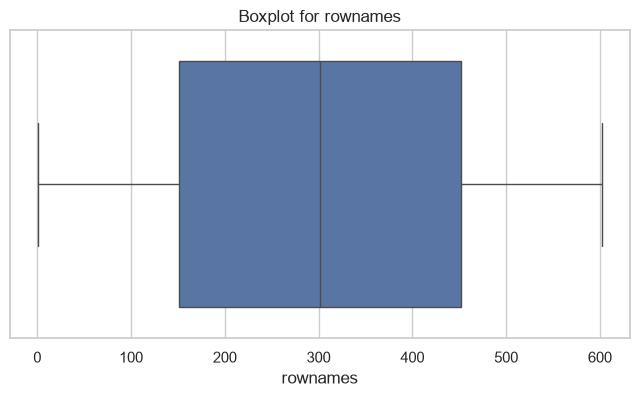

IQR outlier count for rownames: 0
Shape after removing IQR outliers from this variable: (602, 33)


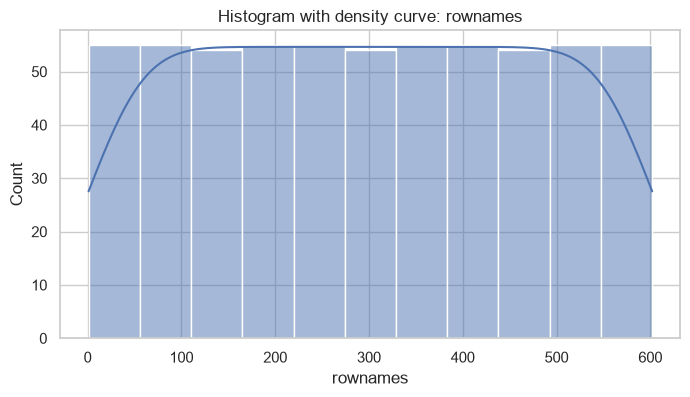

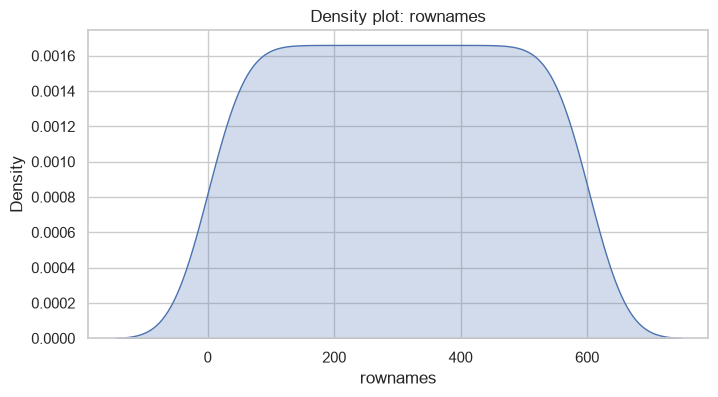

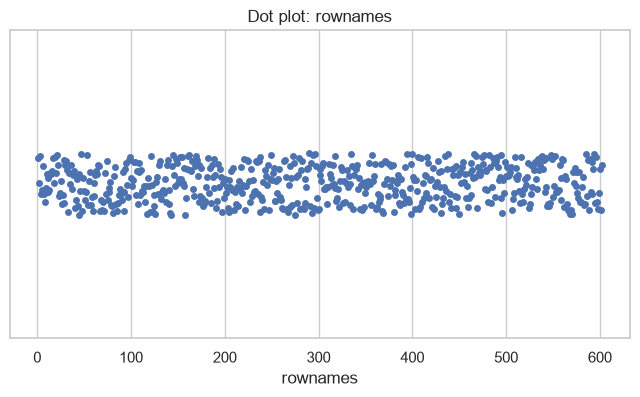

,frequency,proportion,percentage
site,,,
2_IU,413,0.686047,68.604651
1_UM,164,0.272425,27.242525
3_UK,22,0.036545,3.654485
4_Case,3,0.004983,0.498339


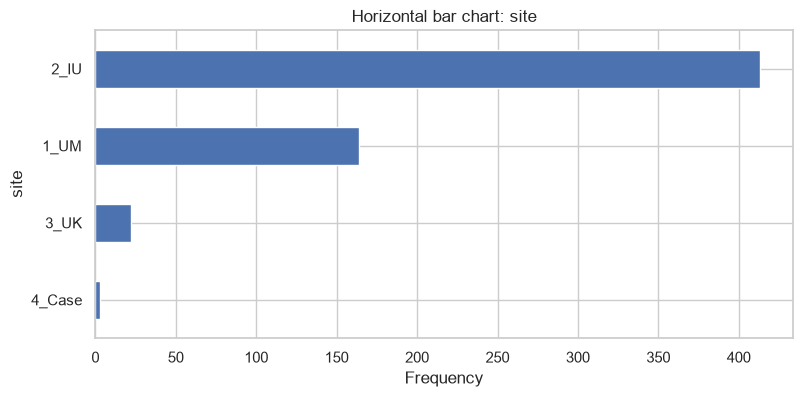

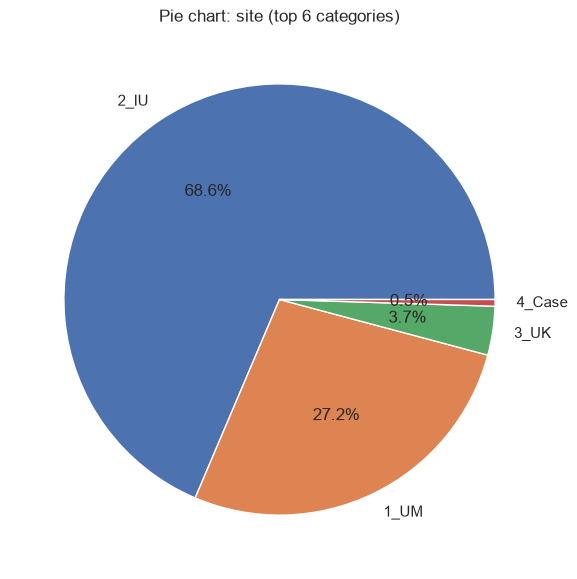

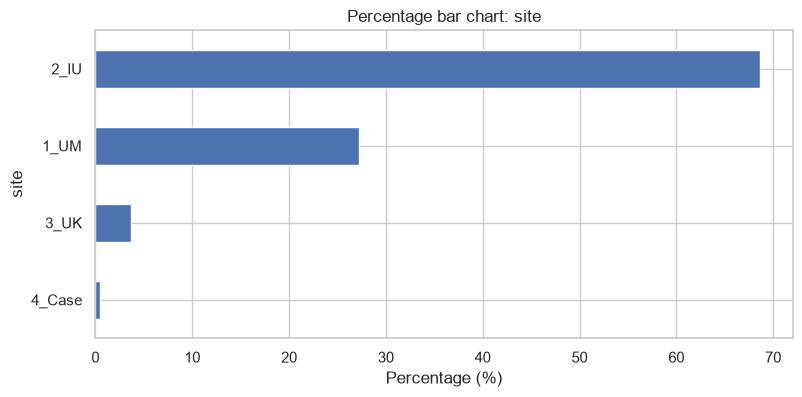

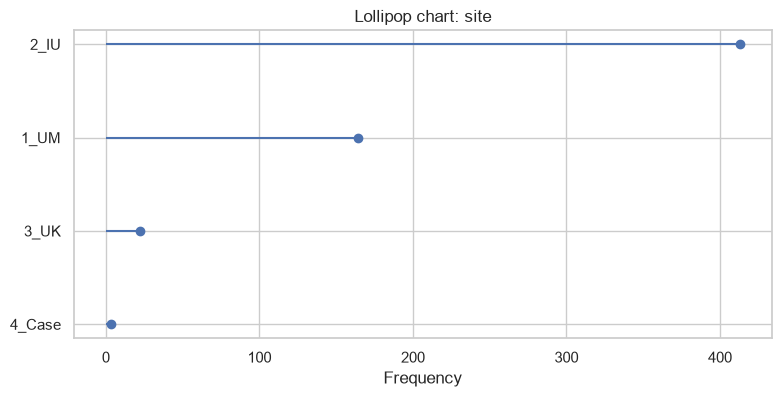

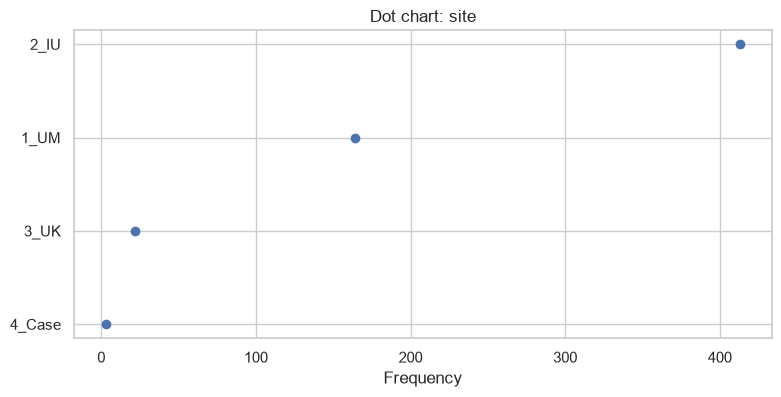

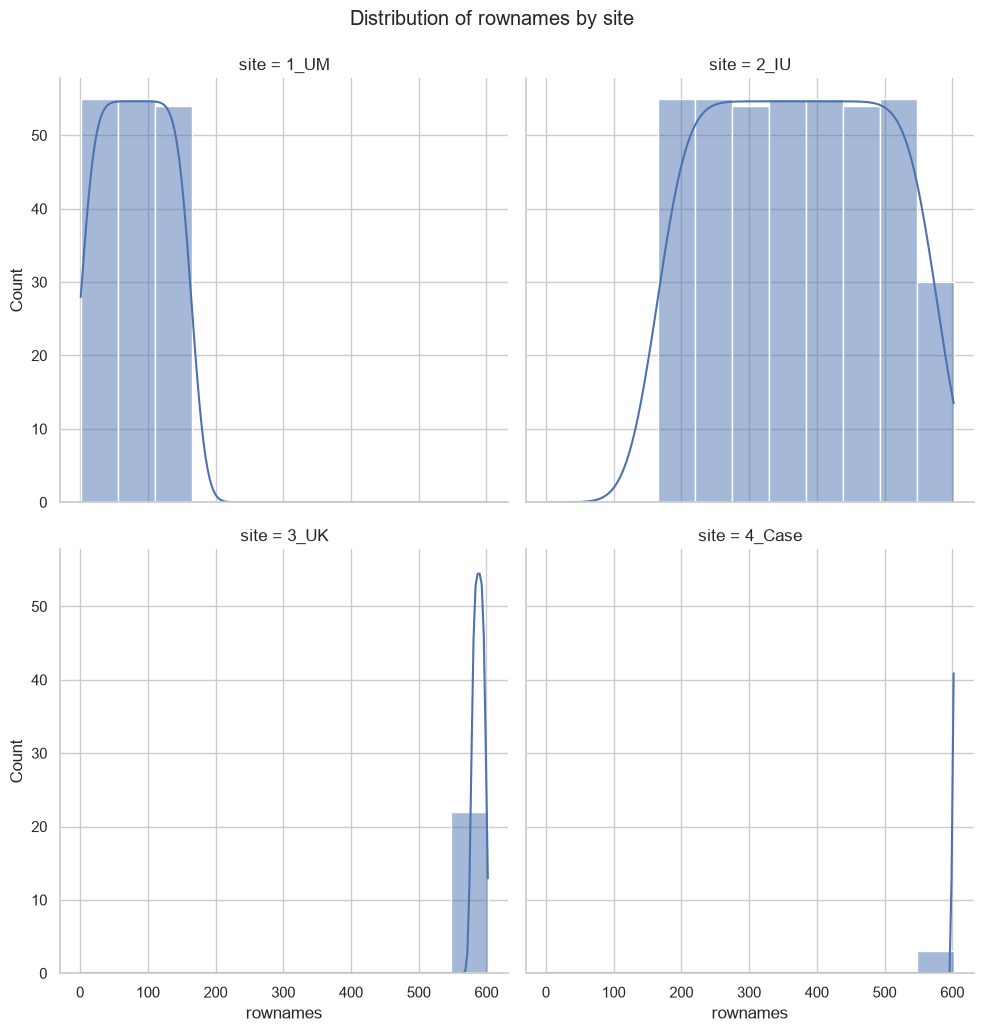

In [6]:
# Remove columns with more than 70% missing values
missing_percent = df.isna().mean() * 100
cols_to_keep = missing_percent[missing_percent <= 70].index
df_clean = df.loc[:, cols_to_keep].copy()
print("Columns removed (>70% missing):", missing_percent[missing_percent > 70].index.tolist())
print("Cleaned shape:", df_clean.shape)

# Impute numerical columns with mean/median, categorical columns with mode
for c in get_numeric_columns(df_clean):
    if df_clean[c].isna().any():
        df_clean[c] = df_clean[c].fillna(df_clean[c].mean())
for c in get_categorical_columns(df_clean):
    if df_clean[c].isna().any():
        m = df_clean[c].mode(dropna=True)
        if not m.empty:
            df_clean[c] = df_clean[c].fillna(m.iloc[0])

print("Duplicate rows before removal:", int(df_clean.duplicated().sum()))
df_clean = df_clean.drop_duplicates().copy()
print("Shape after duplicate removal:", df_clean.shape)

# Convert text columns to categorical and demonstrate case conversion on a copy
for c in get_categorical_columns(df_clean):
    df_clean[c] = df_clean[c].astype("category")
text_cols = df.select_dtypes(include="object").columns.tolist()
if text_cols:
    txt = text_cols[0]
    print("Lowercase example for", txt)
    display(df[txt].dropna().astype(str).str.lower().head())
    print("Uppercase example for", txt)
    display(df[txt].dropna().astype(str).str.upper().head())

# Outlier detection, histogram + density, violin and dot plot
num_cols = get_numeric_columns(df_clean)
cat_cols = get_categorical_columns(df_clean)
if num_cols:
    xcol = num_cols[0]
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df_clean[xcol])
    plt.title(f"Boxplot for {xcol}")
    plt.show()

    x = df_clean[xcol].dropna()
    q1, q3 = x.quantile(.25), x.quantile(.75)
    iqr = q3-q1
    lower, upper = q1-1.5*iqr, q3+1.5*iqr
    outliers = df_clean[(df_clean[xcol] < lower) | (df_clean[xcol] > upper)]
    print(f"IQR outlier count for {xcol}:", len(outliers))
    df_no_extreme = df_clean[df_clean[xcol].between(lower, upper)].copy()
    print("Shape after removing IQR outliers from this variable:", df_no_extreme.shape)

    plt.figure(figsize=(8, 4))
    sns.histplot(df_clean[xcol], kde=True)
    plt.title(f"Histogram with density curve: {xcol}")
    plt.xlabel(xcol); plt.ylabel("Count")
    plt.show()

    plt.figure(figsize=(8, 4))
    sns.kdeplot(data=df_clean, x=xcol, fill=True)
    plt.title(f"Density plot: {xcol}")
    plt.show()

    plt.figure(figsize=(8, 4))
    sns.stripplot(x=df_clean[xcol], jitter=True)
    plt.title(f"Dot plot: {xcol}")
    plt.show()

if cat_cols:
    ccol = cat_cols[0]
    freq = df_clean[ccol].value_counts(dropna=False)
    rel = df_clean[ccol].value_counts(normalize=True, dropna=False)
    freq_table = pd.DataFrame({"frequency": freq, "proportion": rel, "percentage": rel*100})
    display(freq_table)
    plt.figure(figsize=(9, 4))
    freq.head(15).sort_values().plot(kind="barh")
    plt.title(f"Horizontal bar chart: {ccol}"); plt.xlabel("Frequency"); plt.ylabel(ccol)
    plt.show()

    plt.figure(figsize=(7, 7))
    freq.head(6).plot(kind="pie", autopct="%1.1f%%")
    plt.title(f"Pie chart: {ccol} (top 6 categories)")
    plt.ylabel("")
    plt.show()

    # Percentage bar chart
    (rel.head(15)*100).sort_values().plot(kind="barh", figsize=(9,4))
    plt.title(f"Percentage bar chart: {ccol}"); plt.xlabel("Percentage (%)"); plt.ylabel(ccol)
    plt.show()

    # Lollipop chart for category frequencies
    top_freq = freq.head(12).sort_values()
    plt.figure(figsize=(9, 4))
    plt.hlines(y=top_freq.index.astype(str), xmin=0, xmax=top_freq.values)
    plt.plot(top_freq.values, top_freq.index.astype(str), "o")
    plt.title(f"Lollipop chart: {ccol}"); plt.xlabel("Frequency")
    plt.show()

    # Dot chart
    plt.figure(figsize=(9,4))
    plt.plot(top_freq.values, top_freq.index.astype(str), "o")
    plt.title(f"Dot chart: {ccol}"); plt.xlabel("Frequency")
    plt.show()

# Faceted distributions by a category if possible
if num_cols and cat_cols:
    use_df = df_clean[[num_cols[0], cat_cols[0]]].dropna()
    top_cats = use_df[cat_cols[0]].value_counts().head(4).index
    use_df = use_df[use_df[cat_cols[0]].isin(top_cats)]
    if not use_df.empty:
        g = sns.displot(data=use_df, x=num_cols[0], col=cat_cols[0], col_wrap=2, kde=True)
        g.fig.suptitle(f"Distribution of {num_cols[0]} by {cat_cols[0]}", y=1.03)
        plt.show()

## Assessment 4 — Bivariate analysis

Contingency table: site by gender


gender,1_female,2_male
site,,
1_UM,110,54
2_IU,345,68
3_UK,18,4
4_Case,3,0


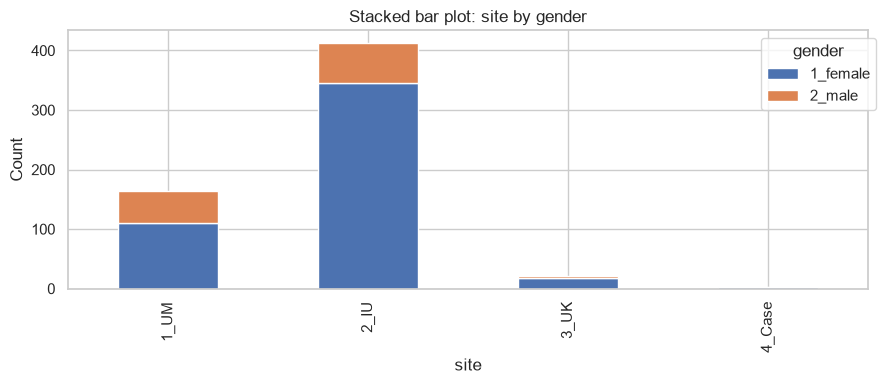

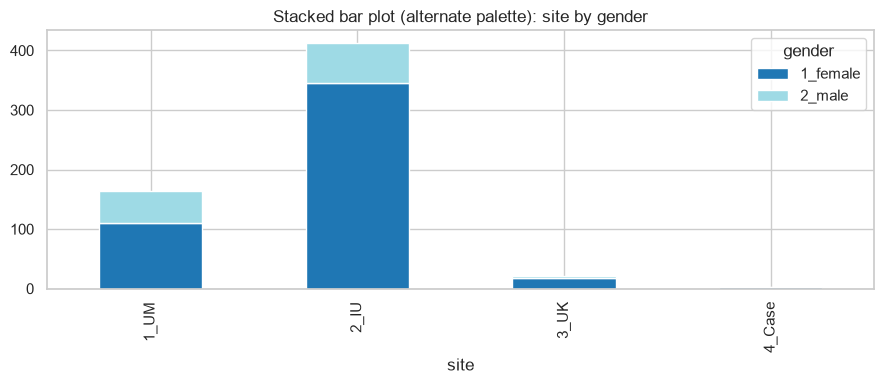

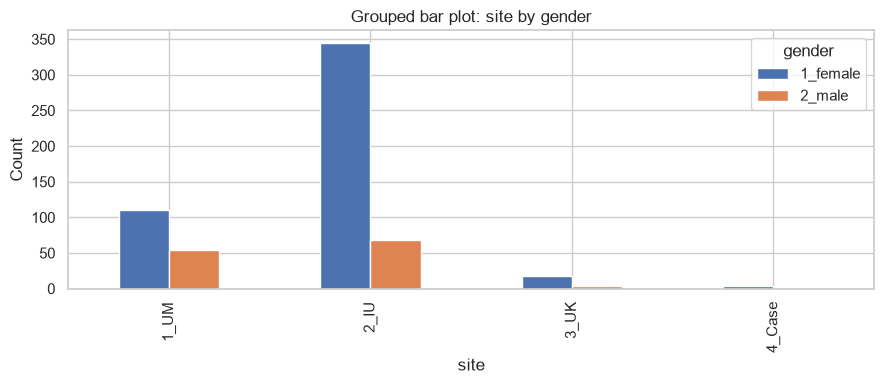

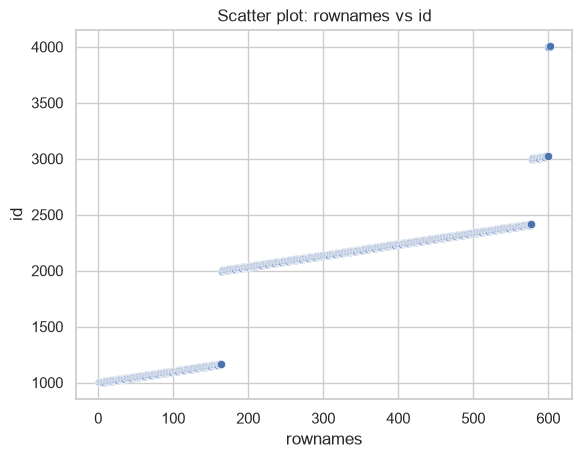

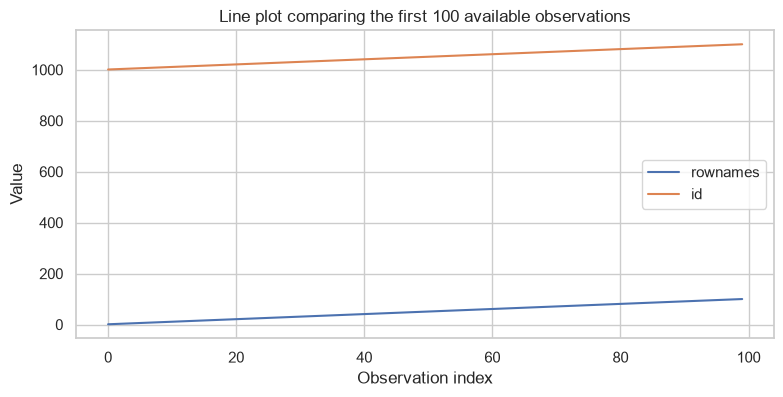

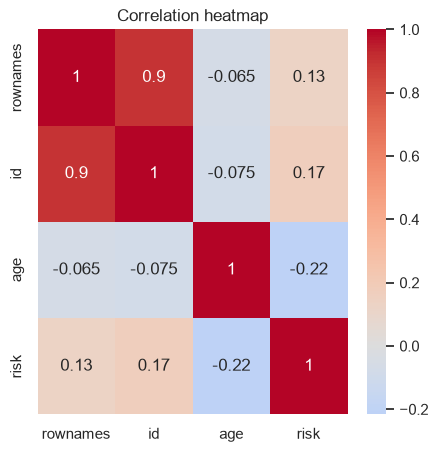

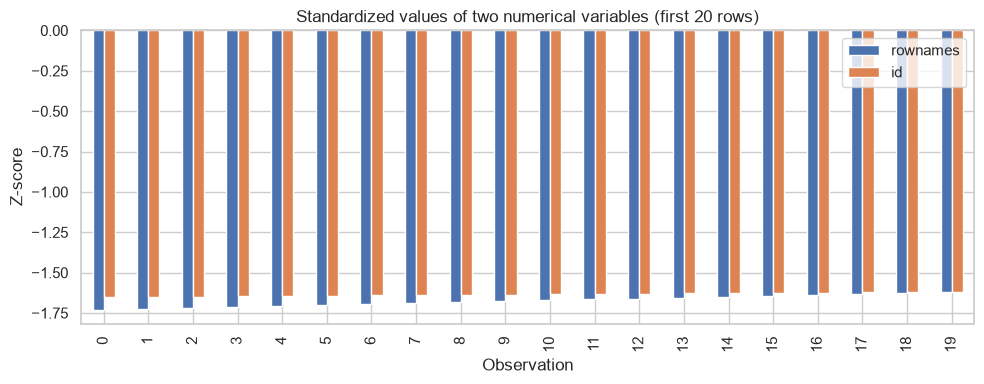

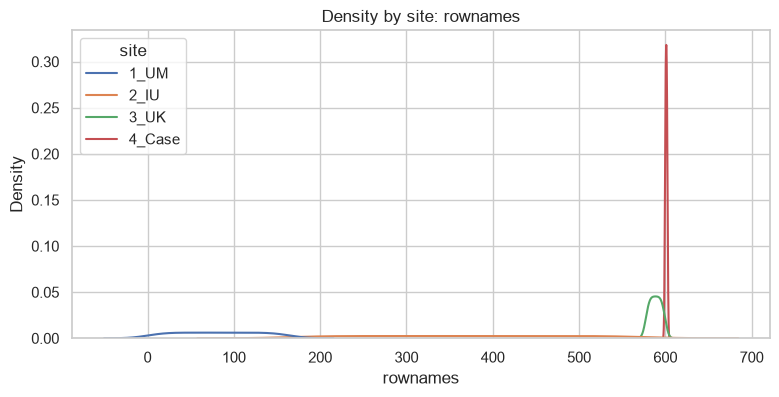

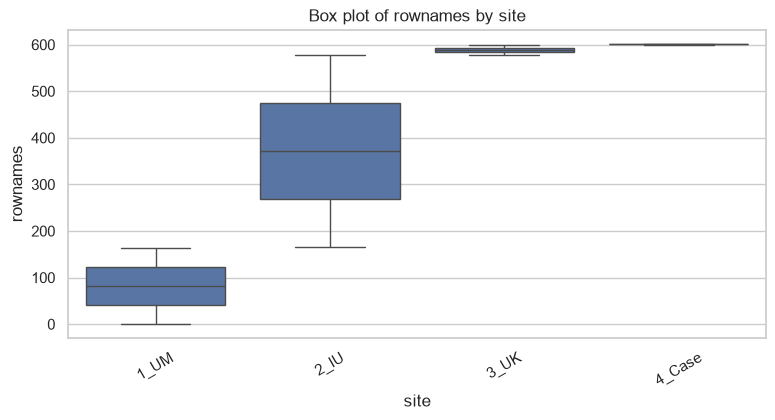

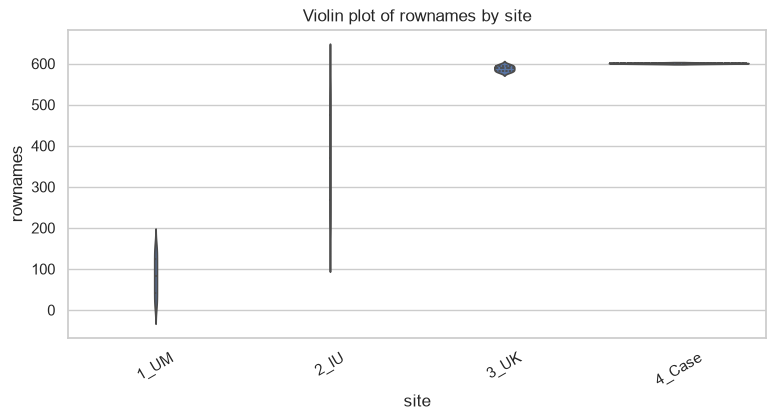

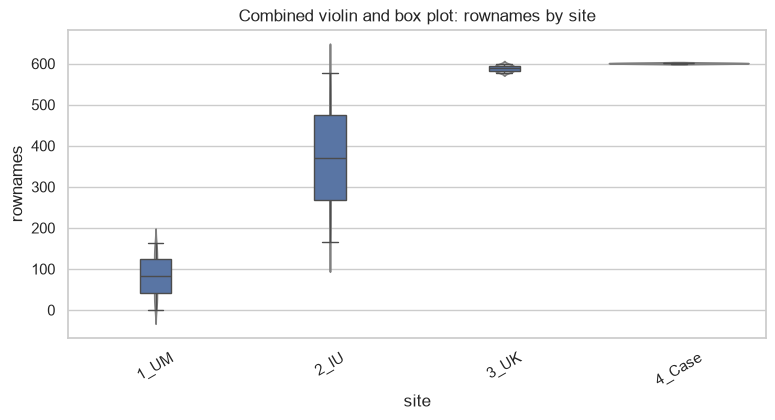

In [7]:
num_cols = get_numeric_columns(df_clean)
cat_cols = get_categorical_columns(df_clean)

# Two categorical variables: contingency table and stacked bar plots
if len(cat_cols) >= 2:
    c1, c2 = cat_cols[:2]
    cross_tab = pd.crosstab(df_clean[c1], df_clean[c2])
    print("Contingency table:", c1, "by", c2)
    display(cross_tab)
    cross_tab.plot(kind="bar", stacked=True, figsize=(9,4))
    plt.title(f"Stacked bar plot: {c1} by {c2}")
    plt.xlabel(c1); plt.ylabel("Count"); plt.legend(title=c2, bbox_to_anchor=(1.02,1))
    plt.tight_layout(); plt.show()
    cross_tab.plot(kind="bar", stacked=True, figsize=(9,4), colormap="tab20")
    plt.title(f"Stacked bar plot (alternate palette): {c1} by {c2}")
    plt.tight_layout(); plt.show()
    cross_tab.plot(kind="bar", figsize=(9,4))
    plt.title(f"Grouped bar plot: {c1} by {c2}")
    plt.ylabel("Count"); plt.tight_layout(); plt.show()

# Two numerical variables: scatter plot, line plot, correlation heatmap
if len(num_cols) >= 2:
    xcol, ycol = num_cols[:2]
    pair = df_clean[[xcol, ycol]].dropna()
    sns.scatterplot(data=pair, x=xcol, y=ycol)
    plt.title(f"Scatter plot: {xcol} vs {ycol}")
    plt.show()

    line_data = pair.reset_index(drop=True).head(100)
    plt.figure(figsize=(9,4))
    plt.plot(line_data[xcol], label=xcol)
    plt.plot(line_data[ycol], label=ycol)
    plt.title("Line plot comparing the first 100 available observations")
    plt.xlabel("Observation index"); plt.ylabel("Value"); plt.legend()
    plt.show()

    corr = df_clean[num_cols].corr(numeric_only=True)
    plt.figure(figsize=(min(12, 1+len(num_cols)), min(9, 1+len(num_cols))))
    sns.heatmap(corr, annot=len(num_cols)<=10, cmap="coolwarm", center=0)
    plt.title("Correlation heatmap")
    plt.show()

    # Bar chart comparing the mean values of two numeric variables (standardized for display)
    z = (pair - pair.mean()) / pair.std(ddof=0)
    z.head(20).plot(kind="bar", figsize=(10,4))
    plt.title("Standardized values of two numerical variables (first 20 rows)")
    plt.xlabel("Observation"); plt.ylabel("Z-score"); plt.tight_layout(); plt.show()

# Numerical variable by category: density, box, violin, combined violin + box
if num_cols and cat_cols:
    ncol, ccol = num_cols[0], cat_cols[0]
    plot_df = df_clean[[ncol, ccol]].dropna()
    top = plot_df[ccol].value_counts().head(6).index
    plot_df = plot_df[plot_df[ccol].isin(top)]
    if not plot_df.empty:
        plt.figure(figsize=(9,4))
        sns.kdeplot(data=plot_df, x=ncol, hue=ccol, common_norm=False)
        plt.title(f"Density by {ccol}: {ncol}"); plt.show()

        plt.figure(figsize=(9,4))
        sns.boxplot(data=plot_df, x=ccol, y=ncol)
        plt.title(f"Box plot of {ncol} by {ccol}"); plt.xticks(rotation=30); plt.show()

        plt.figure(figsize=(9,4))
        sns.violinplot(data=plot_df, x=ccol, y=ncol, inner="quartile")
        plt.title(f"Violin plot of {ncol} by {ccol}"); plt.xticks(rotation=30); plt.show()

        plt.figure(figsize=(9,4))
        sns.violinplot(data=plot_df, x=ccol, y=ncol, inner=None, color="lightgray")
        sns.boxplot(data=plot_df, x=ccol, y=ncol, width=.18)
        plt.title(f"Combined violin and box plot: {ncol} by {ccol}"); plt.xticks(rotation=30); plt.show()

## Assessment 5 — Multivariate analysis

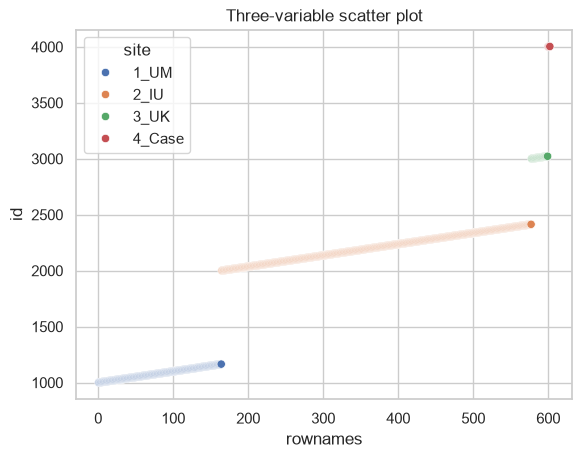

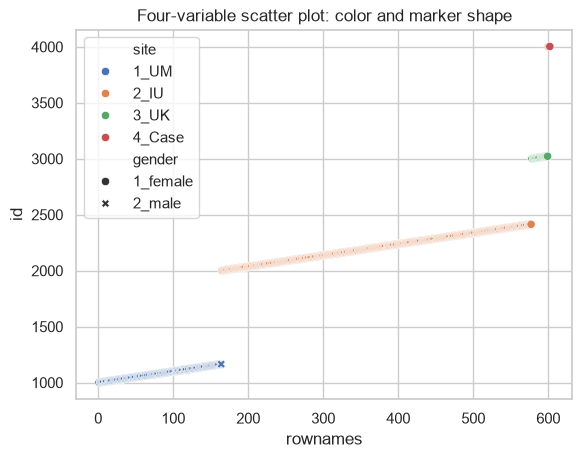

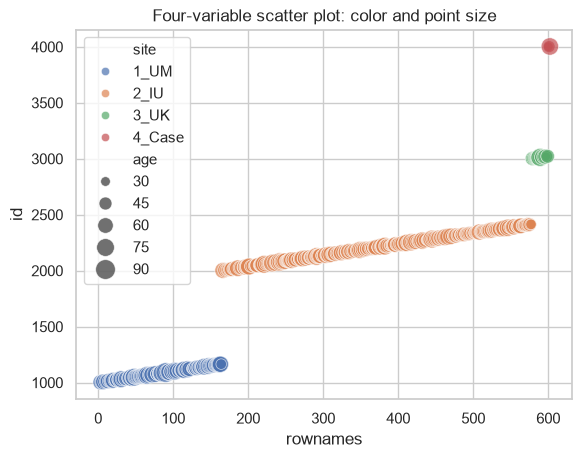

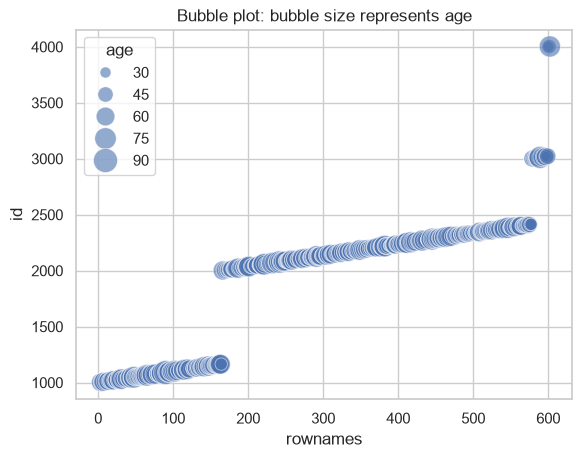

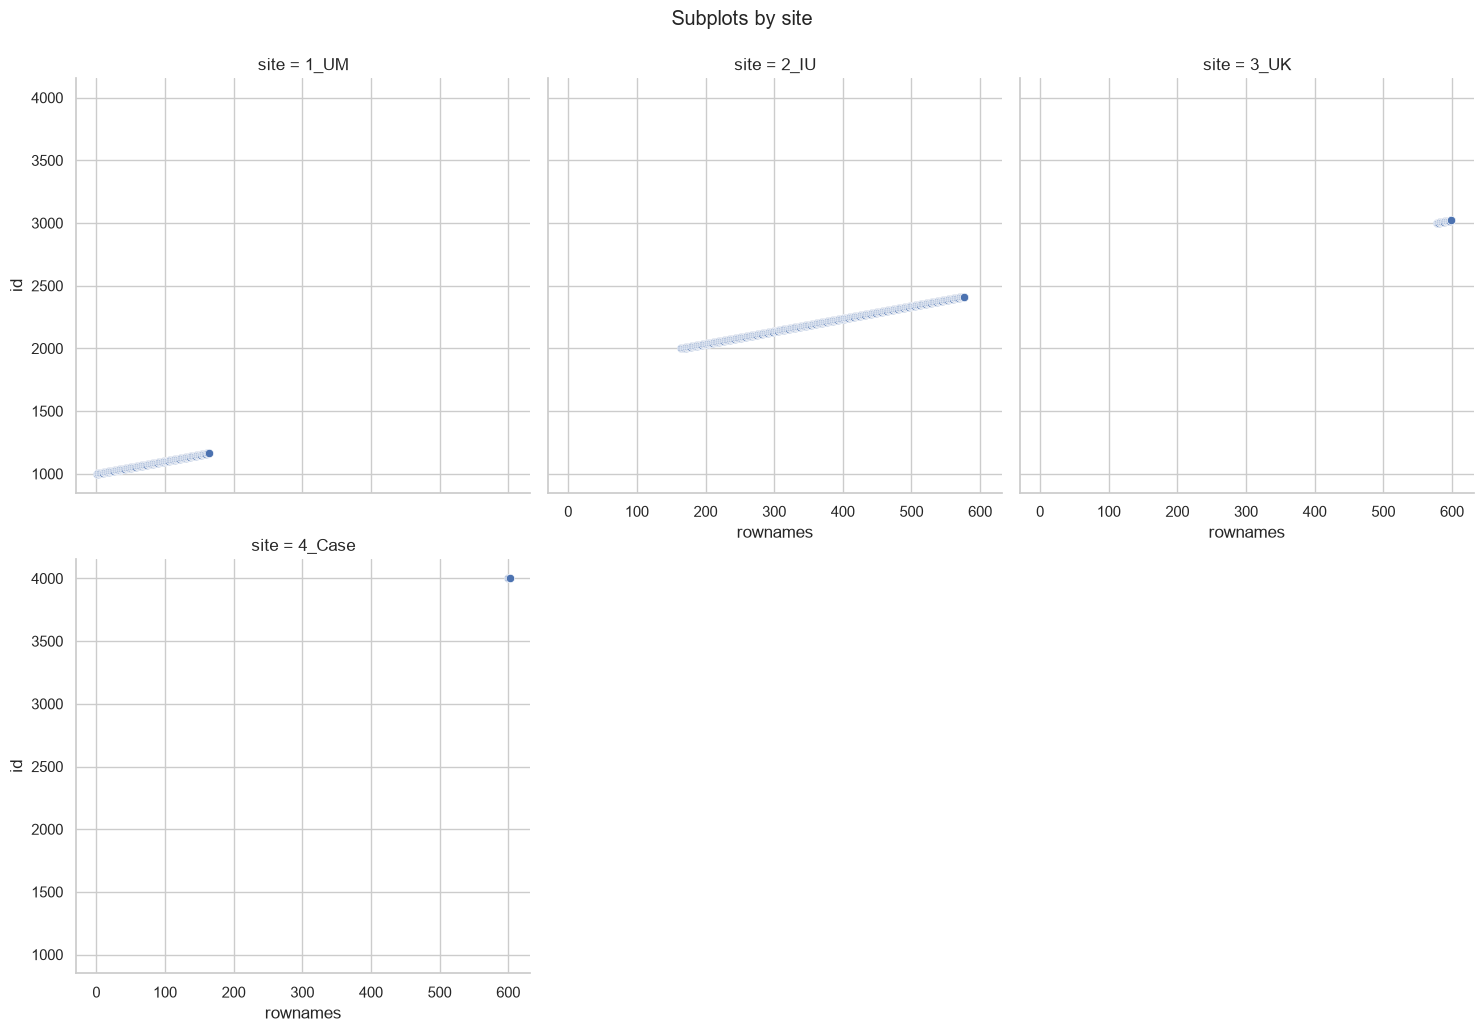

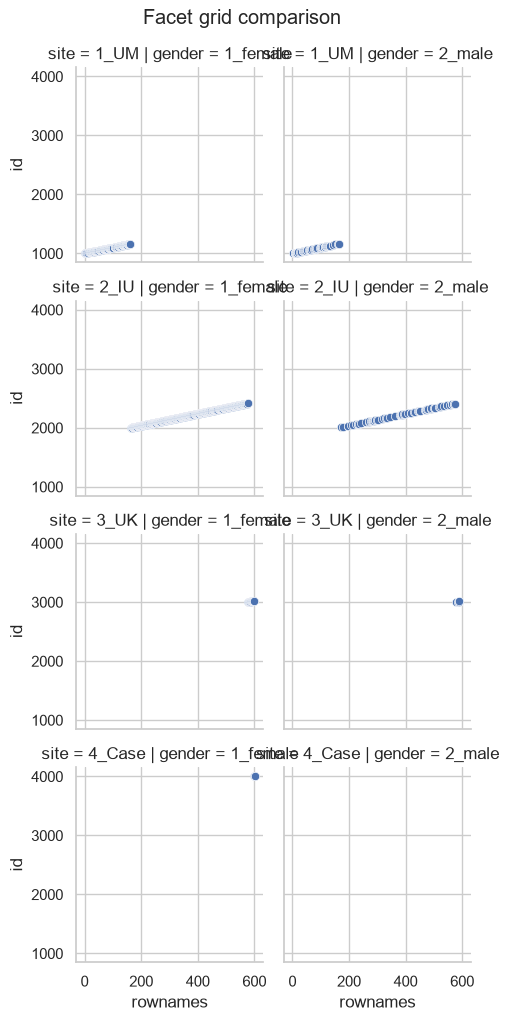

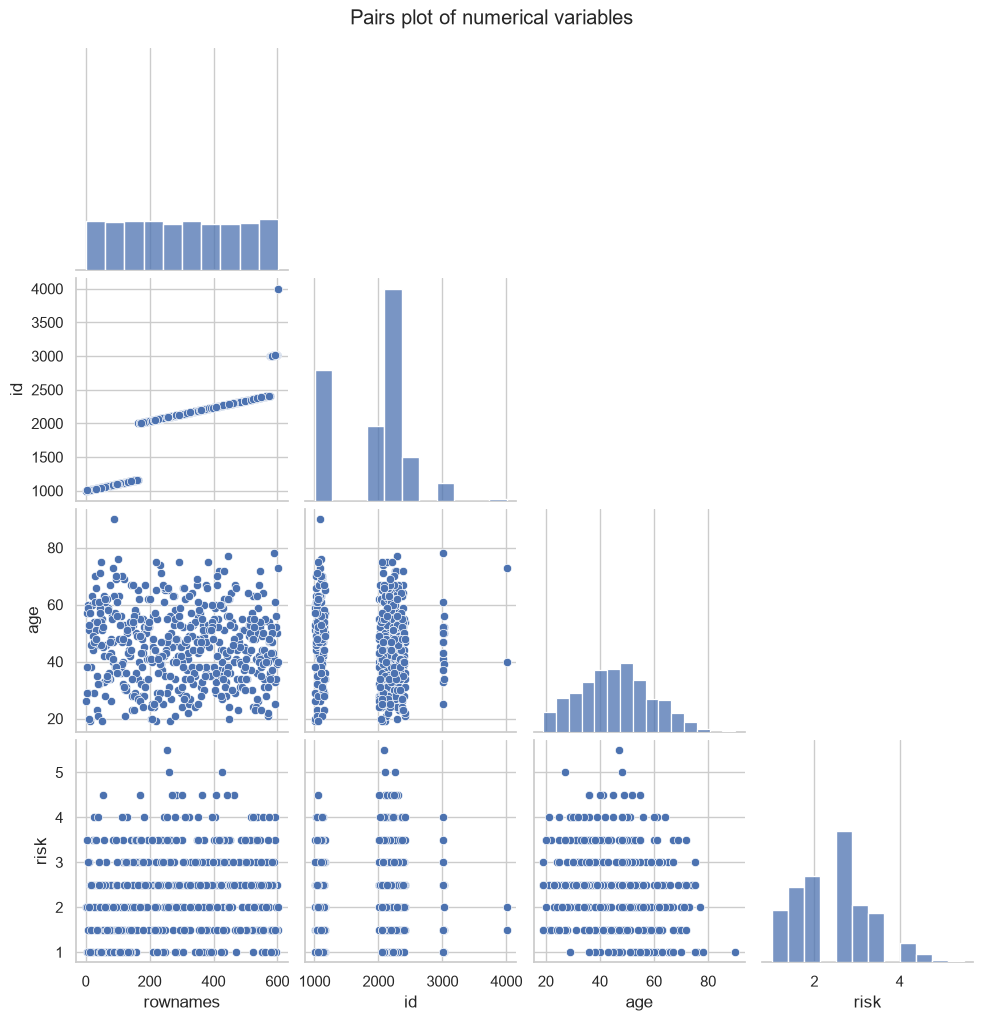

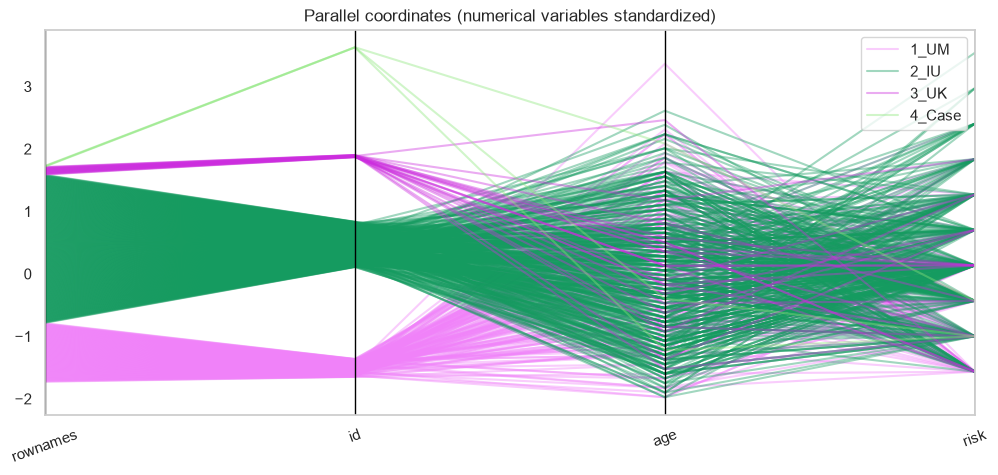

In [8]:
num_cols = get_numeric_columns(df_clean)
cat_cols = get_categorical_columns(df_clean)

if len(num_cols) >= 2 and cat_cols:
    xcol, ycol, color_col = num_cols[0], num_cols[1], cat_cols[0]
    plot_df = df_clean[[xcol, ycol, color_col]].dropna()
    top = plot_df[color_col].value_counts().head(8).index
    plot_df = plot_df[plot_df[color_col].isin(top)]
    sns.scatterplot(data=plot_df, x=xcol, y=ycol, hue=color_col)
    plt.title("Three-variable scatter plot"); plt.show()

    if len(cat_cols) >= 2:
        shape_col = cat_cols[1]
        plot_df2 = df_clean[[xcol, ycol, color_col, shape_col]].dropna()
        plot_df2 = plot_df2[plot_df2[color_col].isin(plot_df2[color_col].value_counts().head(6).index)]
        plot_df2 = plot_df2[plot_df2[shape_col].isin(plot_df2[shape_col].value_counts().head(5).index)]
        sns.scatterplot(data=plot_df2, x=xcol, y=ycol, hue=color_col, style=shape_col)
        plt.title("Four-variable scatter plot: color and marker shape"); plt.show()

    if len(num_cols) >= 3:
        size_col = num_cols[2]
        plot_df3 = df_clean[[xcol, ycol, color_col, size_col]].dropna()
        sns.scatterplot(data=plot_df3, x=xcol, y=ycol, hue=color_col, size=size_col, sizes=(20,200), alpha=.7)
        plt.title("Four-variable scatter plot: color and point size"); plt.show()

        sns.scatterplot(data=df_clean, x=xcol, y=ycol, size=size_col, sizes=(20,300), alpha=.6)
        plt.title(f"Bubble plot: bubble size represents {size_col}"); plt.show()

    # Facet wrap equivalent
    g = sns.relplot(data=plot_df, x=xcol, y=ycol, col=color_col, col_wrap=3, kind="scatter")
    g.fig.suptitle(f"Subplots by {color_col}", y=1.03); plt.show()

    if len(cat_cols) >= 2:
        row_col, col_col = cat_cols[:2]
        grid_data = df_clean[[xcol, ycol, row_col, col_col]].dropna()
        row_levels = grid_data[row_col].value_counts().head(4).index
        col_levels = grid_data[col_col].value_counts().head(4).index
        grid_data = grid_data[grid_data[row_col].isin(row_levels) & grid_data[col_col].isin(col_levels)]
        g = sns.relplot(data=grid_data, x=xcol, y=ycol, row=row_col, col=col_col, kind="scatter", height=2.5)
        g.fig.suptitle("Facet grid comparison", y=1.02); plt.show()

# Pairs plot using at least four numerical columns if available
if len(num_cols) >= 2:
    selected = num_cols[:min(5, len(num_cols))]
    pair_df = df_clean[selected].dropna()
    if len(pair_df) > 500:
        pair_df = pair_df.sample(500, random_state=RANDOM_STATE)
    sns.pairplot(pair_df, corner=True)
    plt.suptitle("Pairs plot of numerical variables", y=1.02); plt.show()

# Parallel coordinates (scale numerical values first)
if len(num_cols) >= 4 and cat_cols:
    from pandas.plotting import parallel_coordinates
    parallel_df = df_clean[num_cols[:4] + [cat_cols[0]]].dropna().copy()
    parallel_df[cat_cols[0]] = parallel_df[cat_cols[0]].astype(str)
    top = parallel_df[cat_cols[0]].value_counts().head(5).index
    parallel_df = parallel_df[parallel_df[cat_cols[0]].isin(top)]
    for c in num_cols[:4]:
        sd = parallel_df[c].std()
        parallel_df[c] = (parallel_df[c]-parallel_df[c].mean()) / (sd if sd else 1)
    plt.figure(figsize=(12,5))
    parallel_coordinates(parallel_df, cat_cols[0], alpha=.4)
    plt.title("Parallel coordinates (numerical variables standardized)")
    plt.xticks(rotation=20); plt.show()
else:
    print("Parallel coordinates needs at least four numerical columns and one categorical column.")

## Assessment 6 — Time-series analysis with AirPassengers

The original task uses R's built-in `AirPassengers` monthly series. Python does not include that exact R object by default, so this cell downloads the public CSV equivalent. If internet access is unavailable, download the CSV first and update `AIR_URL` to its local path.

First five observations


,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


Last five observations


,Passengers
Month,
1960-08-01,606
1960-09-01,508
1960-10-01,461
1960-11-01,390
1960-12-01,432


Start: 1949-01-01 00:00:00 | End: 1960-12-01 00:00:00
Frequency: monthly (12 observations per year)
Series length: 144


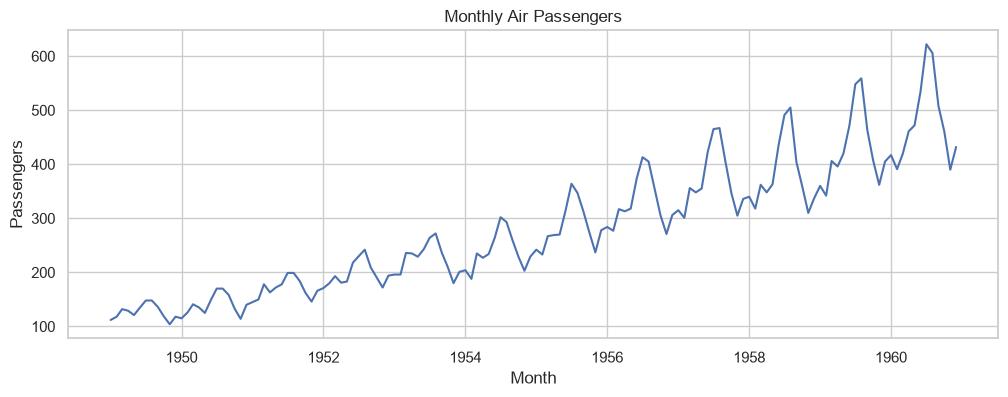

In [9]:
AIR_URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
try:
    air = pd.read_csv(AIR_URL)
    # Expected columns in the public CSV are Month and Passengers
    air.columns = [c.strip() for c in air.columns]
    date_col = next((c for c in air.columns if c.lower() in ["month", "date"]), air.columns[0])
    value_col = next((c for c in air.columns if "passenger" in c.lower()), air.columns[-1])
    air[date_col] = pd.to_datetime(air[date_col])
    air = air.rename(columns={date_col: "Month", value_col: "Passengers"}).set_index("Month")
    air = air.asfreq("MS")
except Exception as e:
    print("Could not download AirPassengers CSV. Error:", e)
    raise

series = air["Passengers"].astype(float)
print("First five observations"); display(air.head())
print("Last five observations"); display(air.tail())
print("Start:", series.index.min(), "| End:", series.index.max())
print("Frequency: monthly (12 observations per year)")
print("Series length:", len(series))

plt.figure(figsize=(12,4))
plt.plot(series)
plt.title("Monthly Air Passengers")
plt.xlabel("Month"); plt.ylabel("Passengers")
plt.show()

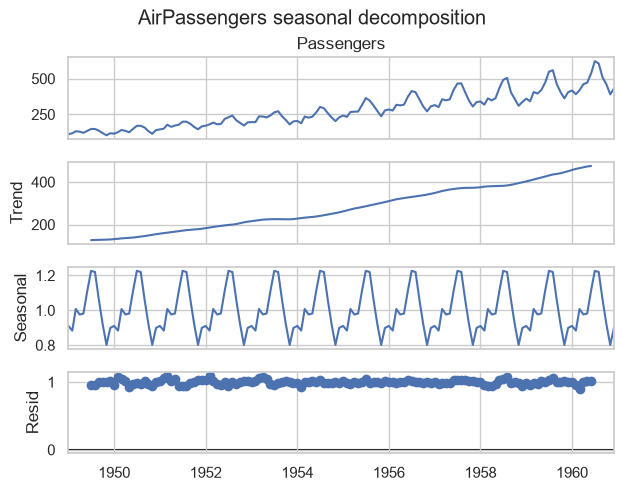

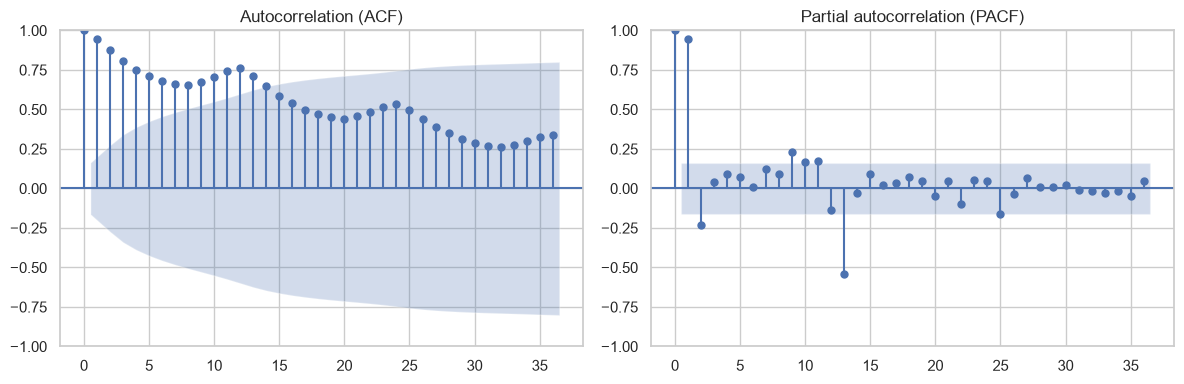

                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  144
Model:                 ARIMA(2, 1, 2)   Log Likelihood                -671.673
Date:                Fri, 16 Oct 2026   AIC                           1353.347
Time:                        20:24:52   BIC                           1368.161
Sample:                    01-01-1949   HQIC                          1359.366
                         - 12-01-1960                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.6850      0.020     83.060      0.000       1.645       1.725
ar.L2         -0.9548      0.017    -55.420      0.000      -0.989      -0.921
ma.L1         -1.8432      0.124    -14.810      0.0

C:\Users\ELCOT\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


,forecast,lower_95,upper_95
1961-01-01,439.854614,389.034986,490.674241
1961-02-01,465.296179,398.585706,532.006653
1961-03-01,500.665701,426.687055,574.644348
1961-04-01,535.971153,459.257306,612.685000
1961-05-01,561.688965,484.137018,639.240913
1961-06-01,571.312619,493.400516,649.224722
1961-07-01,562.972065,484.492450,641.451681
1961-08-01,539.728972,459.554223,619.903721
1961-09-01,508.527913,424.138945,592.916882
1961-10-01,478.147189,386.238624,570.055753


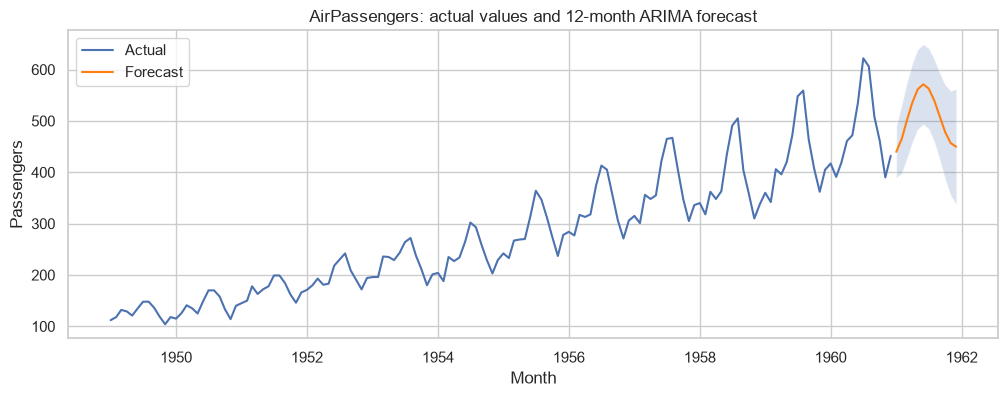

In [10]:
# Decompose into trend, seasonal and residual components
from statsmodels.tsa.seasonal import seasonal_decompose
decomposition = seasonal_decompose(series, model="multiplicative", period=12)
decomposition.plot()
plt.suptitle("AirPassengers seasonal decomposition", y=1.02)
plt.show()

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
fig, ax = plt.subplots(1, 2, figsize=(12,4))
plot_acf(series, lags=36, ax=ax[0]); ax[0].set_title("Autocorrelation (ACF)")
plot_pacf(series, lags=36, ax=ax[1], method="ywm"); ax[1].set_title("Partial autocorrelation (PACF)")
plt.tight_layout(); plt.show()

# Fit ARIMA model. A simple non-seasonal ARIMA is shown to mirror the assessment;
# monthly passenger data is seasonal, so a seasonal model can often fit better.
from statsmodels.tsa.arima.model import ARIMA
arima_model = ARIMA(series, order=(2,1,2)).fit()
print(arima_model.summary())

forecast_result = arima_model.get_forecast(steps=12)
forecast_mean = forecast_result.predicted_mean
forecast_ci = forecast_result.conf_int()
future_index = pd.date_range(series.index[-1] + pd.offsets.MonthBegin(1), periods=12, freq="MS")
forecast_mean.index = future_index
forecast_ci.index = future_index
print("Forecast for next 12 months:")
display(pd.DataFrame({"forecast": forecast_mean, "lower_95": forecast_ci.iloc[:,0], "upper_95": forecast_ci.iloc[:,1]}))

plt.figure(figsize=(12,4))
plt.plot(series, label="Actual")
plt.plot(forecast_mean, label="Forecast", color="tab:orange")
plt.fill_between(forecast_ci.index, forecast_ci.iloc[:,0], forecast_ci.iloc[:,1], alpha=.2)
plt.title("AirPassengers: actual values and 12-month ARIMA forecast")
plt.xlabel("Month"); plt.ylabel("Passengers"); plt.legend()
plt.show()

## Assessment 7 — One-dimensional, two-dimensional and n-dimensional analysis

,variable,mean,median,minimum,maximum,range,variance,standard_deviation,IQR,skewness,kurtosis
0,rownames,301.5,301.5,1,602,601,30250.5,173.926709,300.5,0.0,-1.2


,frequency,relative_frequency,percentage
site,,,
2_IU,413,0.686047,68.604651
1_UM,164,0.272425,27.242525
3_UK,22,0.036545,3.654485
4_Case,3,0.004983,0.498339


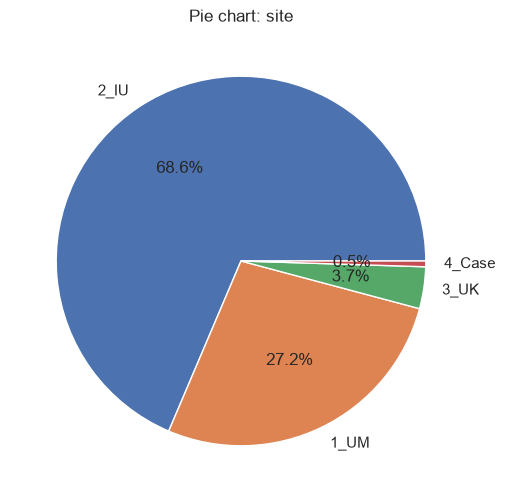

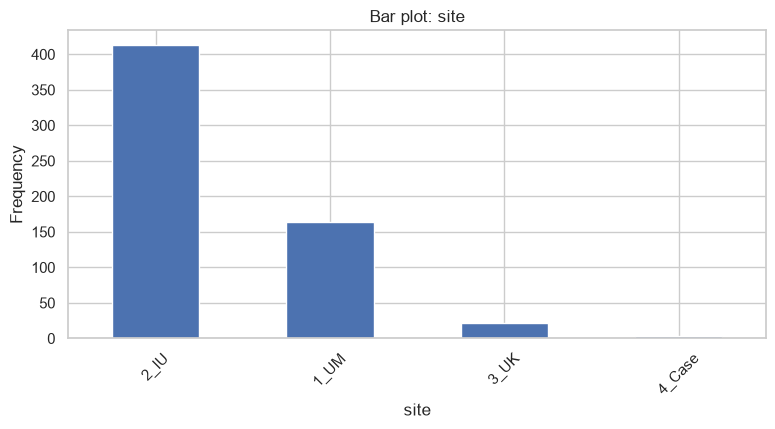

,frequency
rownames,
"(0.399, 61.1]",61
"(61.1, 121.2]",60
"(121.2, 181.3]",60
"(181.3, 241.4]",60
"(241.4, 301.5]",60
"(301.5, 361.6]",60
"(361.6, 421.7]",60
"(421.7, 481.8]",60
"(481.8, 541.9]",60


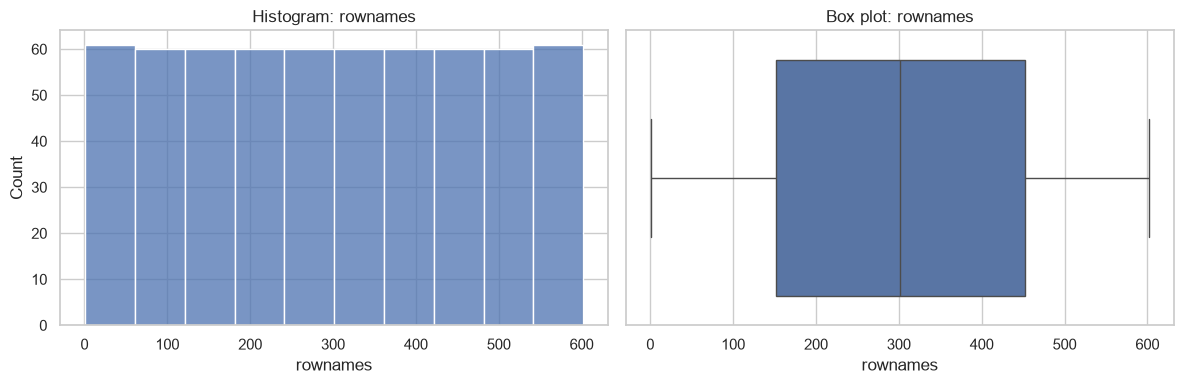

Contingency table


gender,1_female,2_male
site,,
1_UM,110,54
2_IU,345,68
3_UK,18,4
4_Case,3,0


Row percentages


gender,1_female,2_male
site,,
1_UM,0.671,0.329
2_IU,0.835,0.165
3_UK,0.818,0.182
4_Case,1.000,0.000


Column percentages


gender,1_female,2_male
site,,
1_UM,0.231,0.429
2_IU,0.725,0.540
3_UK,0.038,0.032
4_Case,0.006,0.000


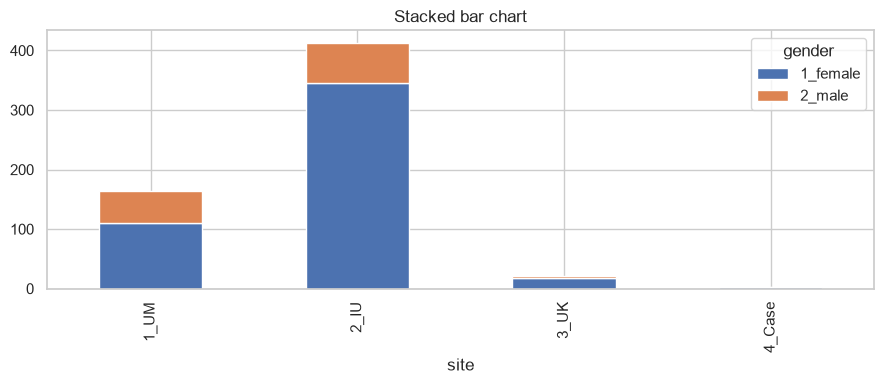

,mean,median,std,count
site,,,,
2_IU,371.0,371.0,119.367081,413
1_UM,82.5,82.5,47.486840,164
3_UK,588.5,588.5,6.493587,22
4_Case,601.0,601.0,1.000000,3


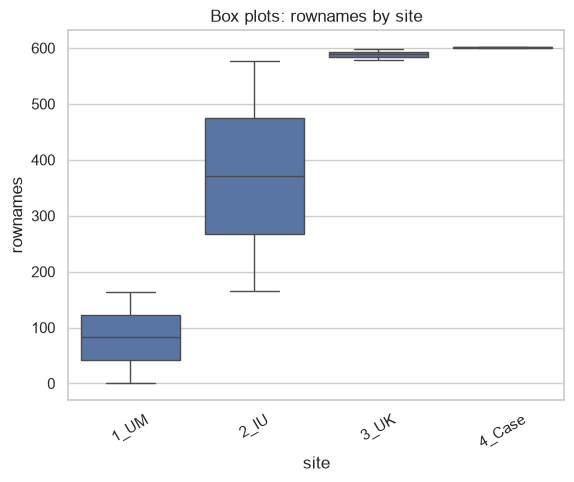

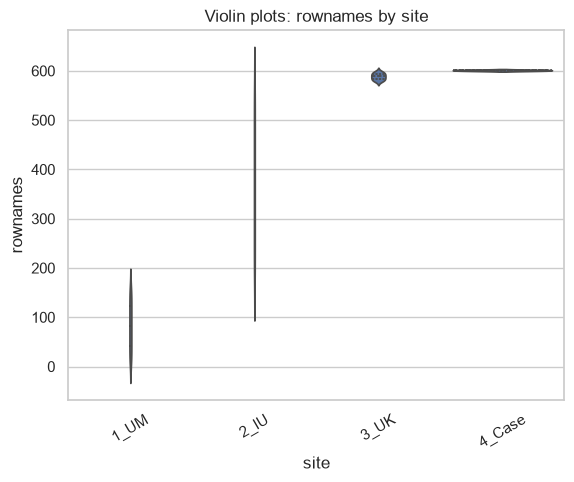

Pearson correlation: 0.8974107613651223
Spearman correlation: 1.0


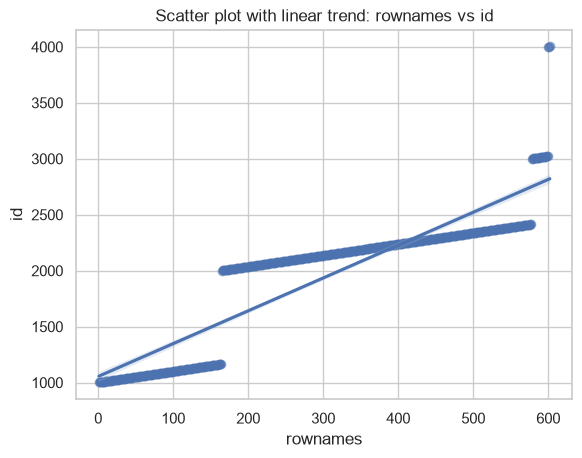

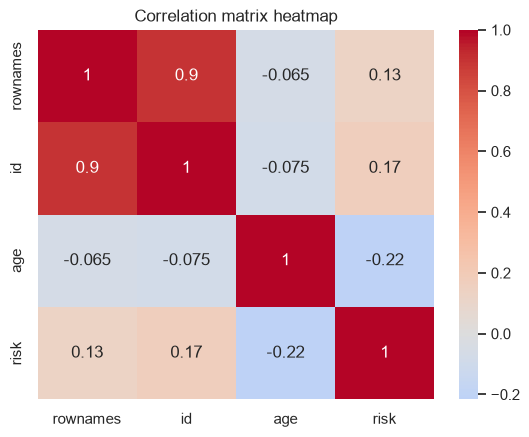

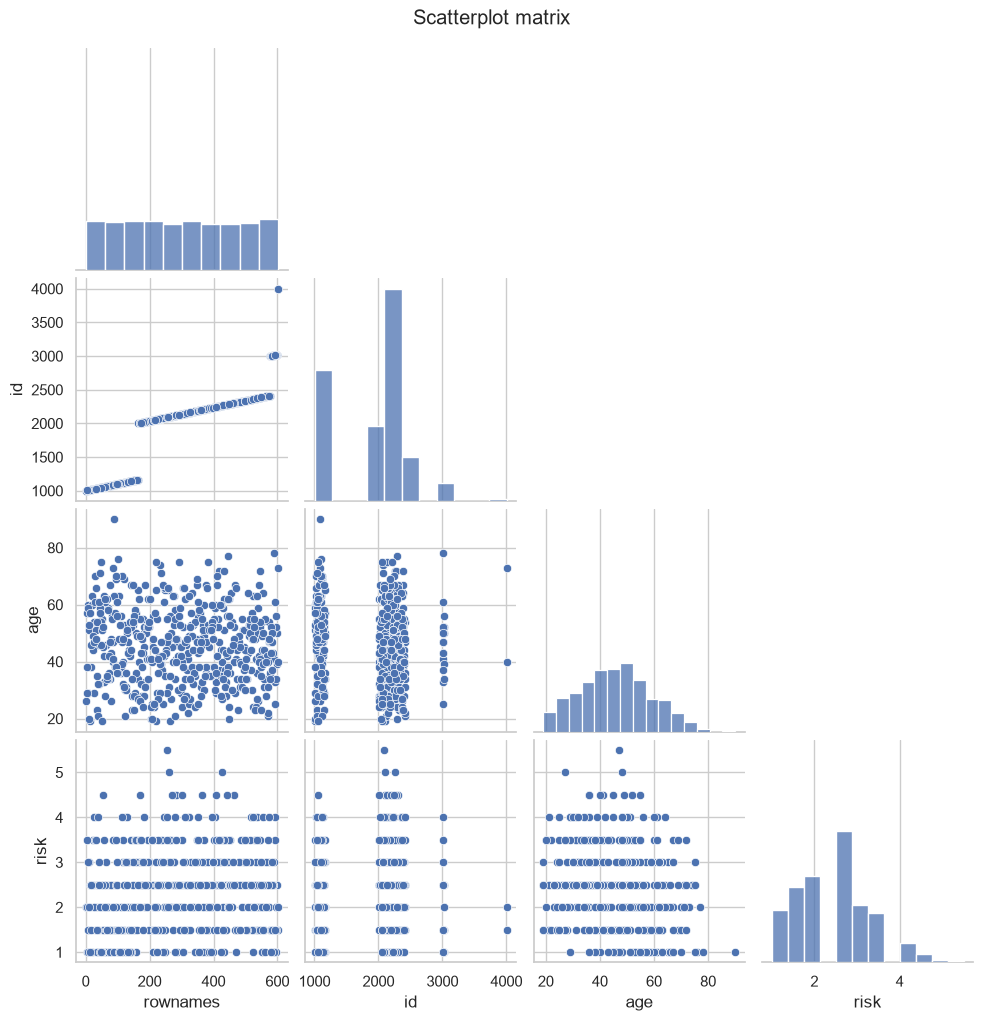

,site,gender,mean,std,count
0,1_UM,1_female,84.981818,47.206939,110
1,1_UM,2_male,77.444444,48.096078,54
2,2_IU,1_female,368.171014,119.621702,345
3,2_IU,2_male,385.352941,117.891648,68
4,3_UK,1_female,589.166667,6.741007,18
5,3_UK,2_male,585.500000,4.795832,4
6,4_Case,1_female,601.000000,1.000000,3
7,4_Case,2_male,NaN,NaN,0


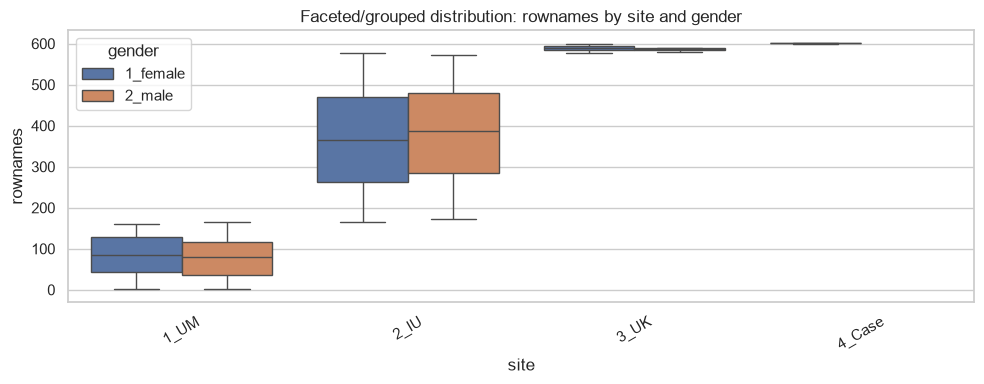

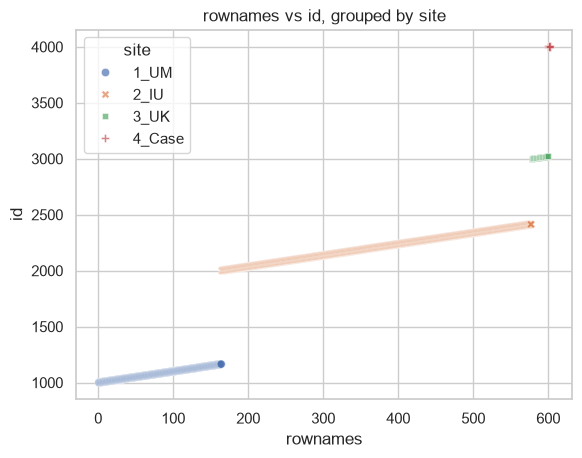

Correlation for site='1_UM': 1.000
Correlation for site='2_IU': 1.000
Correlation for site='3_UK': 1.000
Correlation for site='4_Case': 1.000


In [11]:
# Summary statistics table for one numeric column
num_cols = get_numeric_columns(df_clean)
cat_cols = get_categorical_columns(df_clean)
if num_cols:
    col = num_cols[0]
    x = df_clean[col].dropna()
    stats_table = pd.DataFrame([{
        "variable": col, "mean": x.mean(), "median": x.median(),
        "minimum": x.min(), "maximum": x.max(), "range": x.max()-x.min(),
        "variance": x.var(), "standard_deviation": x.std(),
        "IQR": x.quantile(.75)-x.quantile(.25),
        "skewness": skew(x, bias=False) if len(x)>2 else np.nan,
        "kurtosis": kurtosis(x, bias=False) if len(x)>3 else np.nan
    }])
    display(stats_table)

# Frequency and relative frequency tables
if cat_cols:
    cat = cat_cols[0]
    freq = df_clean[cat].value_counts(dropna=False)
    freq_table = pd.DataFrame({"frequency": freq, "relative_frequency": freq/freq.sum(), "percentage": 100*freq/freq.sum()})
    display(freq_table)
    freq.head(10).plot(kind="pie", autopct="%1.1f%%", figsize=(6,6))
    plt.title(f"Pie chart: {cat}"); plt.ylabel(""); plt.show()
    freq.head(15).plot(kind="bar", figsize=(9,4))
    plt.title(f"Bar plot: {cat}"); plt.ylabel("Frequency"); plt.xticks(rotation=45); plt.show()

# Numerical frequency bins, histogram and boxplot
if num_cols:
    num = num_cols[0]
    bins = pd.cut(df_clean[num], bins=10)
    display(bins.value_counts().sort_index().to_frame("frequency"))
    fig, ax = plt.subplots(1,2,figsize=(12,4))
    sns.histplot(df_clean[num], bins=10, ax=ax[0]); ax[0].set_title(f"Histogram: {num}")
    sns.boxplot(x=df_clean[num], ax=ax[1]); ax[1].set_title(f"Box plot: {num}")
    plt.tight_layout(); plt.show()

# Contingency table and row/column percentages
if len(cat_cols) >= 2:
    ct = pd.crosstab(df_clean[cat_cols[0]], df_clean[cat_cols[1]])
    print("Contingency table"); display(ct)
    print("Row percentages"); display(ct.div(ct.sum(axis=1), axis=0).round(3))
    print("Column percentages"); display(ct.div(ct.sum(axis=0), axis=1).round(3))
    ct.plot(kind="bar", stacked=True, figsize=(9,4))
    plt.title("Stacked bar chart"); plt.tight_layout(); plt.show()

# Grouped numerical statistics and side-by-side box/violin plots
if num_cols and cat_cols:
    n, c = num_cols[0], cat_cols[0]
    grouped = df_clean.groupby(c, observed=False)[n].agg(["mean","median","std","count"]).sort_values("count", ascending=False)
    display(grouped.head(15))
    top = grouped.head(8).index
    plot_df = df_clean[df_clean[c].isin(top)][[c,n]].dropna()
    sns.boxplot(data=plot_df, x=c, y=n); plt.title(f"Box plots: {n} by {c}"); plt.xticks(rotation=30); plt.show()
    sns.violinplot(data=plot_df, x=c, y=n, inner="quartile"); plt.title(f"Violin plots: {n} by {c}"); plt.xticks(rotation=30); plt.show()

# Correlation, regression line and pair plot
if len(num_cols) >= 2:
    n1,n2 = num_cols[:2]
    pair = df_clean[[n1,n2]].dropna()
    print("Pearson correlation:", pair[n1].corr(pair[n2], method="pearson"))
    print("Spearman correlation:", pair[n1].corr(pair[n2], method="spearman"))
    sns.regplot(data=pair, x=n1, y=n2, scatter_kws={"alpha":.5})
    plt.title(f"Scatter plot with linear trend: {n1} vs {n2}"); plt.show()
    corr = df_clean[num_cols].corr()
    sns.heatmap(corr, annot=len(num_cols)<=8, cmap="coolwarm", center=0)
    plt.title("Correlation matrix heatmap"); plt.show()
    selected = num_cols[:min(5,len(num_cols))]
    sample = df_clean[selected].dropna()
    if len(sample)>500: sample = sample.sample(500, random_state=RANDOM_STATE)
    sns.pairplot(sample, corner=True); plt.suptitle("Scatterplot matrix", y=1.02); plt.show()

# Combined two-category + one-numeric summaries and category-wise correlations
if len(cat_cols) >= 2 and num_cols:
    a,b,n = cat_cols[0],cat_cols[1],num_cols[0]
    combo = df_clean.groupby([a,b], observed=False)[n].agg(["mean","std","count"]).reset_index()
    display(combo.head(20))
    plt.figure(figsize=(10,4))
    sns.boxplot(data=df_clean, x=a, y=n, hue=b)
    plt.title(f"Faceted/grouped distribution: {n} by {a} and {b}")
    plt.xticks(rotation=30); plt.tight_layout(); plt.show()

if cat_cols and len(num_cols)>=2:
    c = cat_cols[0]; a,b = num_cols[:2]
    sns.scatterplot(data=df_clean, x=a, y=b, hue=c, style=c, alpha=.7)
    plt.title(f"{a} vs {b}, grouped by {c}"); plt.show()
    for level, part in df_clean.groupby(c, observed=False):
        if len(part[[a,b]].dropna()) >= 3:
            print(f"Correlation for {c}={level!r}: {part[a].corr(part[b]):.3f}")

## Assessment 8 — K-Means and hierarchical clustering

K-Means cluster assignments (first 20): [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Cluster centers in standardized space:


,rownames,id,age,risk
0,-1.260198,-1.507647,0.146792,-0.360240
1,0.471855,0.564507,-0.054963,0.134884


Cluster sizes:


,count
0,164
1,438


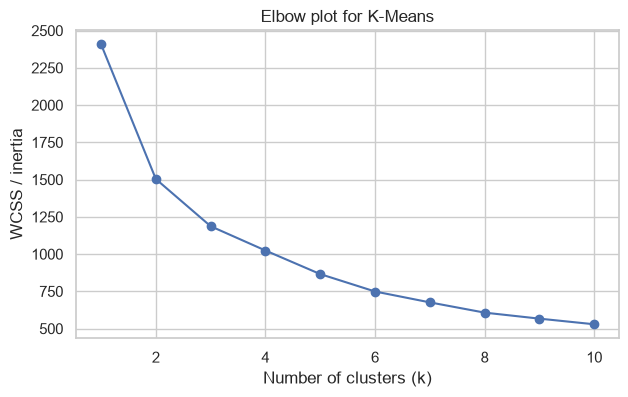

Final K-Means labels with k=3 (first 20): [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


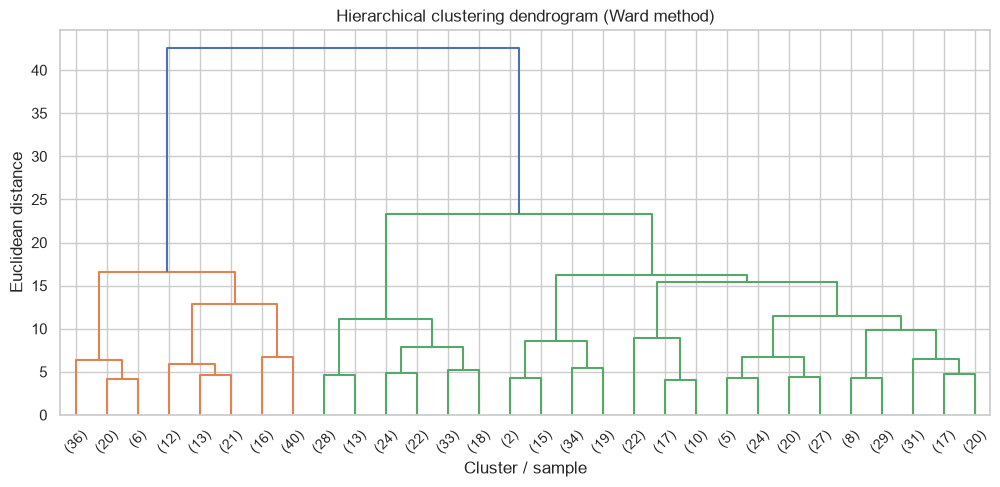

Hierarchical cluster counts:


,count
0,164
1,300
2,138


In [12]:
# Prepare numerical features and impute missing values using each column's median
cluster_num_cols = get_numeric_columns(df_clean)
if len(cluster_num_cols) < 2:
    print("Clustering needs at least two numerical columns.")
else:
    cluster_data = df_clean[cluster_num_cols].replace([np.inf, -np.inf], np.nan)
    cluster_data = cluster_data.fillna(cluster_data.median()).dropna(axis=1, how="all")
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(cluster_data)

    # K-means with k=2
    kmeans2 = KMeans(n_clusters=2, random_state=RANDOM_STATE, n_init=10)
    labels2 = kmeans2.fit_predict(X_scaled)
    print("K-Means cluster assignments (first 20):", labels2[:20])
    print("Cluster centers in standardized space:")
    display(pd.DataFrame(kmeans2.cluster_centers_, columns=cluster_data.columns))
    print("Cluster sizes:")
    display(pd.Series(labels2).value_counts().sort_index().to_frame("count"))

    # WCSS/inertia for k=1..10
    max_k = min(10, len(cluster_data))
    inertias = []
    for k in range(1, max_k+1):
        model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
        model.fit(X_scaled)
        inertias.append(model.inertia_)
    plt.figure(figsize=(7,4))
    plt.plot(range(1,max_k+1), inertias, marker="o")
    plt.title("Elbow plot for K-Means"); plt.xlabel("Number of clusters (k)"); plt.ylabel("WCSS / inertia")
    plt.show()

    # Choose k=3 as a transparent demonstration; inspect elbow before final selection.
    chosen_k = min(3, len(cluster_data))
    kmeans_final = KMeans(n_clusters=chosen_k, random_state=RANDOM_STATE, n_init=10)
    final_labels = kmeans_final.fit_predict(X_scaled)
    print(f"Final K-Means labels with k={chosen_k} (first 20):", final_labels[:20])

    # Hierarchical clustering with Ward's method
    # Limit sample size to keep pairwise distance calculation manageable
    max_rows = 1500
    if len(X_scaled) > max_rows:
        rng = np.random.default_rng(RANDOM_STATE)
        idx = np.sort(rng.choice(len(X_scaled), max_rows, replace=False))
        X_hier = X_scaled[idx]
    else:
        idx = np.arange(len(X_scaled))
        X_hier = X_scaled
    Z = linkage(X_hier, method="ward", metric="euclidean")
    plt.figure(figsize=(12,5))
    dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=45)
    plt.title("Hierarchical clustering dendrogram (Ward method)")
    plt.xlabel("Cluster / sample"); plt.ylabel("Euclidean distance")
    plt.show()

    hierarchical = AgglomerativeClustering(n_clusters=3, linkage="ward")
    h_labels = hierarchical.fit_predict(X_hier)
    print("Hierarchical cluster counts:")
    display(pd.Series(h_labels).value_counts().sort_index().to_frame("count"))

## Assessment 9 — Principal Component Analysis (PCA)

Dataset rows and columns: (602, 33)
PCA summary:


,Principal Component,Explained Variance (%),Cumulative Variance (%)
0,PC1,49.183,49.183
1,PC2,28.838,78.020
2,PC3,19.432,97.452
3,PC4,2.548,100.000


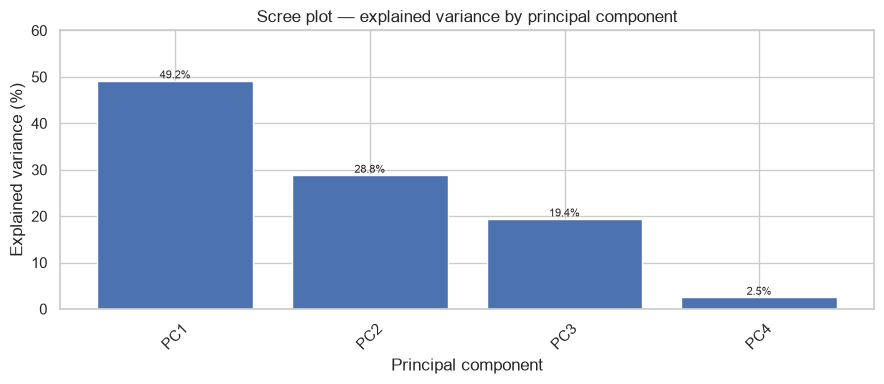

First six PCA scores:


,PC1,PC2
0,-2.173820,-1.432184
1,-2.423438,-0.816930
2,-2.796696,0.973166
3,-2.192982,-1.265006
4,-1.874650,-1.858876
5,-2.249144,-0.358106


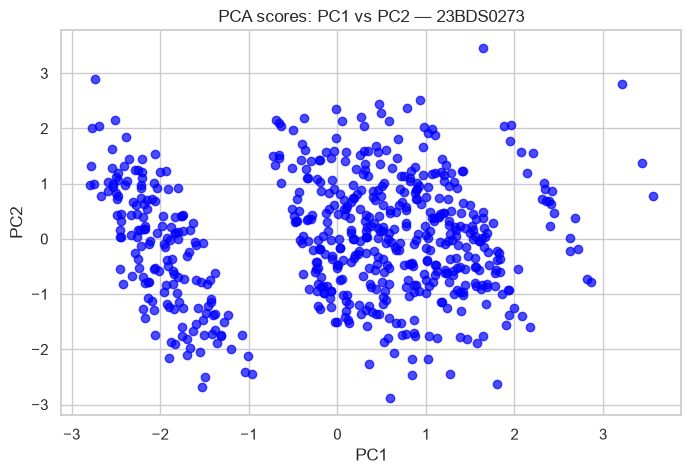

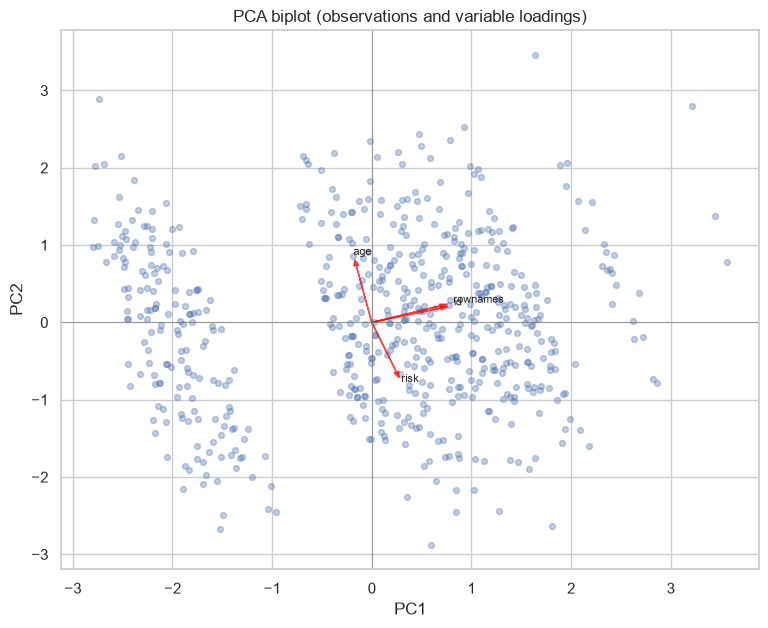

In [13]:
# Select numeric data, replace infinities, median-impute missing values and standardize
pca_cols = get_numeric_columns(df_clean)
if len(pca_cols) < 2:
    print("PCA needs at least two numerical columns.")
else:
    pca_data = df_clean[pca_cols].replace([np.inf, -np.inf], np.nan)
    pca_data = pca_data.fillna(pca_data.median())
    pca_data = pca_data.dropna(axis=1, how="all")
    scaler = StandardScaler()
    data_scaled = scaler.fit_transform(pca_data)
    print("Dataset rows and columns:", df_clean.shape)

    pca = PCA()
    pca_result = pca.fit_transform(data_scaled)
    variance_table = pd.DataFrame({
        "Principal Component": [f"PC{i+1}" for i in range(len(pca.explained_variance_ratio_))],
        "Explained Variance (%)": pca.explained_variance_ratio_ * 100,
        "Cumulative Variance (%)": np.cumsum(pca.explained_variance_ratio_) * 100
    })
    print("PCA summary:")
    display(variance_table.round(3))

    # Scree plot; y-axis limit 0–60 as required
    plt.figure(figsize=(9,4))
    pc_names = [f"PC{i+1}" for i in range(len(pca.explained_variance_ratio_))]
    plt.bar(pc_names, pca.explained_variance_ratio_*100)
    for i, val in enumerate(pca.explained_variance_ratio_*100):
        plt.text(i, val, f"{val:.1f}%", ha="center", va="bottom", fontsize=8)
    plt.ylim(0,60)
    plt.title("Scree plot — explained variance by principal component")
    plt.xlabel("Principal component"); plt.ylabel("Explained variance (%)")
    plt.xticks(rotation=45); plt.tight_layout(); plt.show()

    # PCA scores and PC1 vs PC2 plot
    pca_scores = pd.DataFrame(pca_result[:, :min(2,pca_result.shape[1])],
                              columns=[f"PC{i+1}" for i in range(min(2,pca_result.shape[1]))],
                              index=pca_data.index)
    print("First six PCA scores:")
    display(pca_scores.head(6))

    if pca_scores.shape[1] >= 2:
        plt.figure(figsize=(8,5))
        plt.scatter(pca_scores["PC1"], pca_scores["PC2"], color="blue", marker="o", alpha=.7)
        plt.title(f"PCA scores: PC1 vs PC2 — {REG_NO}")
        plt.xlabel("PC1"); plt.ylabel("PC2"); plt.show()

    # Biplot-style visualization: observations + variable loading arrows
    if pca_result.shape[1] >= 2:
        loadings = pca.components_.T[:, :2]
        plt.figure(figsize=(9,7))
        plt.scatter(pca_result[:,0], pca_result[:,1], alpha=.35, s=18)
        scale = max(np.std(pca_result[:,0]), np.std(pca_result[:,1])) * 0.8
        for i, name in enumerate(pca_data.columns):
            plt.arrow(0, 0, loadings[i,0]*scale, loadings[i,1]*scale,
                      color="red", alpha=.7, head_width=.05, length_includes_head=True)
            plt.text(loadings[i,0]*scale*1.08, loadings[i,1]*scale*1.08, name, fontsize=8)
        plt.title("PCA biplot (observations and variable loadings)")
        plt.xlabel("PC1"); plt.ylabel("PC2"); plt.axhline(0, color="gray", lw=.5); plt.axvline(0, color="gray", lw=.5)
        plt.show()

## Notes for interpretation
- **Missing values:** report the actual counts printed by your run; do not invent values.
- **Outliers:** the IQR rule flags unusual values, but an outlier is not automatically an error.
- **Correlation:** describes association, not proof that one variable causes another.
- **Clustering:** cluster labels are group IDs, not rankings or class labels.
- **PCA:** each principal component is a combination of original numerical variables. Explained variance tells how much variation each component captures.
- **Time-series forecast:** ARIMA forecasts are estimates and include uncertainty. The simple non-seasonal model is included to demonstrate the requested workflow; seasonal models may be more suitable for monthly passenger data.